# Capstone Viggy — Sleep-EDF

## Como usar este notebook

| Fase | Para quê? | Quando executar? |
|---|---|---|
| **1 — Preparar a sessão** | Preparar os programas, ligar o Drive e definir as opções. | Sempre que o Colab iniciar uma sessão nova. |
| **2 — Experiências nos oito participantes** | Consultar B0, F1, F2, C1, P1 e a análise dos sinais. | Só quando quiseres repetir essas experiências. Está desligada por defeito. |
| **3 — Trabalho nos 68 participantes** | Usar a divisão fixa A–E e continuar o download. | É a etapa atual. O download só corre quando o ativares. |

**Agora:** executa apenas a Fase 1. Depois podes consultar o estado dos ficheiros em **3.2**, sem descarregar nem treinar.
Usa os títulos no índice lateral do Colab para navegar. Não precisas de usar «Executar tudo».

As tabelas e figuras já guardadas na Fase 2 são resultados anteriores. Não significam que esses treinos tenham sido repetidos nesta sessão.
Os resultados guardados no Drive continuam nos seus ficheiros JSON, mesmo que não voltes a executar as células antigas.

Código do professor: `5949b723bbd34d172f072446dfcb802ef54b49f7`.


## Fase 1 — Executar ao abrir uma sessão nova

Esta fase não descarrega o Sleep-EDF nem treina modelos. Prepara os programas e liga a mesma pasta do Drive.
Se a sessão continuar ligada e as variáveis ainda existirem, não é necessário repetir a preparação.

### 1.1 — Preparar os programas

Mantém a versão do código do professor usada nas experiências anteriores. Só instala pacotes em falta.


In [ ]:
%matplotlib inline
import importlib.util
import importlib.metadata
import json
import os
import subprocess
import sys
from pathlib import Path

COURSE_REVISION = "5949b723bbd34d172f072446dfcb802ef54b49f7"
COURSE_URL = "https://github.com/farhad-abtahi/CM2013.git"
COURSE_DIR = Path("_bsp_repo").resolve()
IN_COLAB = "google.colab" in sys.modules

# Use the same instructor code that produced the saved baseline.
# Existing checkouts are checked rather than reset.
if not (COURSE_DIR / ".git").is_dir():
    if COURSE_DIR.exists() and any(COURSE_DIR.iterdir()):
        raise RuntimeError(f"{COURSE_DIR} is not an empty course checkout.")
    COURSE_DIR.mkdir(parents=True, exist_ok=True)
    subprocess.run(["git", "init", "--quiet", str(COURSE_DIR)], check=True)
    subprocess.run(["git", "-C", str(COURSE_DIR), "remote", "add", "origin", COURSE_URL],
                   check=True)
    subprocess.run(["git", "-C", str(COURSE_DIR), "fetch", "--quiet", "--depth", "1",
                    "origin", COURSE_REVISION], check=True)
    subprocess.run(["git", "-C", str(COURSE_DIR), "checkout", "--quiet",
                    "--detach", "FETCH_HEAD"], check=True)

course_revision_loaded = subprocess.check_output(
    ["git", "-C", str(COURSE_DIR), "rev-parse", "HEAD"], text=True
).strip()
if course_revision_loaded != COURSE_REVISION:
    raise RuntimeError(
        f"The existing course checkout is {course_revision_loaded}, "
        f"but this baseline uses {COURSE_REVISION}. Use a separate checkout "
        "or a fresh Colab runtime; keep any edits in the existing checkout."
    )

packages = {
    "numpy": "numpy", "scipy": "scipy", "matplotlib": "matplotlib",
    "sklearn": "scikit-learn", "mne": "mne", "imblearn": "imbalanced-learn",
}
missing_packages = [
    distribution for module, distribution in packages.items()
    if importlib.util.find_spec(module) is None
]
if missing_packages:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing_packages],
                   check=True)

for subfolder in ("tracks", "src", "src/bsp"):
    entry = str(COURSE_DIR / subfolder)
    if entry not in sys.path:
        sys.path.insert(0, entry)

import sleep_edf
from sleep_edf import SleepEDFTrack
import bookstyle as bs
import numpy as np
import matplotlib.pyplot as plt

if Path(sleep_edf.__file__).resolve().parent != COURSE_DIR / "tracks":
    raise RuntimeError("A different sleep_edf module is already loaded. Restart the runtime.")

USE_REAL = True
BASELINE_CONFIG = {}

runtime_versions = {"python": sys.version.split()[0]}
for distribution in packages.values():
    try:
        runtime_versions[distribution] = importlib.metadata.version(distribution)
    except importlib.metadata.PackageNotFoundError:
        runtime_versions[distribution] = "not installed"

print("environment :", "colab" if IN_COLAB else sys.platform)
print("USE_REAL    :", USE_REAL)
print("course code :", course_revision_loaded)
print("runtime     :", json.dumps(runtime_versions, sort_keys=True))


environment : colab
USE_REAL    : True
course code : 5949b723bbd34d172f072446dfcb802ef54b49f7
runtime     : {"imbalanced-learn": "0.14.2", "matplotlib": "3.10.0", "mne": "1.13.2", "numpy": "2.1.3", "python": "3.13.18", "scikit-learn": "1.6.1", "scipy": "1.16.3"}


### 1.2 — Ligar o Google Drive e definir os caminhos

Usamos uma única pasta de dados: `/content/drive/MyDrive/CM2013_data`.
Ligar novamente o Drive não copia a pasta. Não mudes estes caminhos só para passar de oito para 68 participantes.


In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

DATA = "/content/drive/MyDrive/CM2013_data"
Path(DATA).mkdir(parents=True, exist_ok=True)

TRAIN_DIR = Path(DATA) / "train"
CACHE_VIGGY = str(Path(DATA) / "cache" / "viggy")
EXPERIMENTS_DIR = Path(DATA) / "experiments"

# Cache dos oito participantes confirmado na sessão anterior.
CACHE_8_FILE = TRAIN_DIR / "_cache_SleepEDFTrack_c036dc141386.pkl"

print("Dados:", TRAIN_DIR)
print("Cache de processamento e características:", CACHE_VIGGY)
print("Resultados:", EXPERIMENTS_DIR)


Mounted at /content/drive
Dados: /content/drive/MyDrive/CM2013_data/train
Cache de processamento e características: /content/drive/MyDrive/CM2013_data/cache/viggy
Resultados: /content/drive/MyDrive/CM2013_data/experiments


### 1.3 — Escolher o que pode executar nesta sessão

Deixa as três opções em `False` por agora. Assim, executar células por engano não inicia os treinos dos oito nem o download dos 68.

- `RUN_8_EXPERIMENTS`: permite repetir as experiências da Fase 2.
- `SAVE_8_REPORTS`: permite voltar a gravar os JSON antigos, substituindo os ficheiros com os mesmos nomes. Só tem efeito se a opção anterior também estiver em `True`.
- `RUN_68_DOWNLOAD`: permite continuar o download em 3.3. Não inicia treino.

Depois de mudar uma opção, executa novamente esta célula e a célula da tarefa que escolheste.


In [ ]:
RUN_8_EXPERIMENTS = False
SAVE_8_REPORTS = False
RUN_68_DOWNLOAD = False

COMPARISON_BUDGET = 12

# Função comum para guardar números e arrays NumPy em JSON.
def converter_numpy(obj):
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, np.generic):
        return obj.item()
    raise TypeError(f"Tipo não suportado: {type(obj).__name__}")

print("Repetir experiências nos oito:", RUN_8_EXPERIMENTS)
print("Voltar a guardar os resultados dos oito:", SAVE_8_REPORTS)
print("Continuar download dos 68:", RUN_68_DOWNLOAD)


Repetir experiências nos oito: False
Voltar a guardar os resultados dos oito: False
Continuar download dos 68: False


### O que fica guardado no Drive?

| Local dentro de `CM2013_data` | O que contém |
|---|---|
| `train/physionet-sleep-data/` | EDF originais e ficheiros com as marcações do sono. O download dos 68 reutiliza os dos oito. |
| `train/_cache_SleepEDFTrack_*.pkl` | Gravações já lidas pelo código. O cache dos oito já existe. |
| `cache/viggy/_cache_viggy_preprocess_*.pkl` | Resultados do processamento de cada gravação. |
| `cache/viggy/_cache_viggy_features_*.pkl` | Características calculadas para cada gravação e configuração. |
| `experiments/` | Resultados em JSON: `features_B0_F1_F2.json`, `C1_crop30.json` e `P1_lowpass35.json`. |

Estes ficheiros têm funções diferentes; um EDF, um cache e um relatório não são três cópias do mesmo ficheiro.
É normal haver vários caches, um por gravação, etapa ou configuração. Manter as mesmas versões e definições permite reutilizá-los.
Esta reorganização não inclui comandos para apagar ou mover dados do Drive.


## Fase 2 — Oito participantes: experiências anteriores

**Consulta esta fase sem a executar.** Para a repetir, ativa `RUN_8_EXPERIMENTS` em 1.3 e corre as células desta fase por ordem.
As células que guardam JSON também exigem `SAVE_8_REPORTS = True`.

Participantes: **SC400–SC407**, 16 gravações, 44 303 épocas. Cada experiência usa oito treinos: treina com sete pessoas e testa na outra.

| Experiência | O que foi comparado | Kappa médio por participante ± desvio-padrão |
|---|---|---|
| B0 | 11 características iniciais + Random Forest | 0.824 ± 0.068 |
| F1 | Substituir as cinco potências por potências relativas | 0.828 ± 0.054 |
| F2 | Juntar as 11 iniciais e as cinco relativas: 16 características | 0.837 ± 0.052 |
| C1 | F2, retirando do treino parte do tempo acordado no início e no fim | 0.813 ± 0.051 |
| P1 | F2 com filtro passa-baixo de 35 Hz no EEG | 0.833 ± 0.054 |

Estes números são dos oito participantes, não dos 68. F2 é a referência inicial a confirmar na fase maior.
Ainda não há resultados confirmados de outro classificador.

### 2.1 — Carregar apenas os oito participantes

Primeiro reutiliza o cache dos oito já existente. Se ele não existir, lê só os EDF desses oito através de ligações temporárias locais.
Não copia EDF para outra pasta do Drive e não lê os 68 todos para repetir esta fase.


In [ ]:
if RUN_8_EXPERIMENTS:
    DEVELOPMENT_SUBJECTS = list(range(8))
else:
    print("Célula opcional não executada.")


Célula opcional não executada.


In [ ]:
if RUN_8_EXPERIMENTS:
    import tempfile

    track = SleepEDFTrack(cfg=BASELINE_CONFIG)
    requested_groups = {f"SC4{int(s):02d}" for s in DEVELOPMENT_SUBJECTS}

    track.download(str(TRAIN_DIR), subset=DEVELOPMENT_SUBJECTS)

    if CACHE_8_FILE.is_file():
        # Este cache já contém só SC400–SC407, mesmo que a pasta tenha mais EDF agora.
        recs = track.load_cached(str(TRAIN_DIR), cache_file=str(CACHE_8_FILE))
    else:
        # A pasta temporária contém apenas ligações aos ficheiros originais.
        # Desaparece depois da leitura; os ficheiros no Drive ficam no mesmo sítio.
        selected_files = sorted(
            p for p in TRAIN_DIR.rglob("*.edf")
            if p.name[:5] in requested_groups
        )
        with tempfile.TemporaryDirectory(prefix="viggy_8_") as tmp:
            for p in selected_files:
                link = Path(tmp) / p.name
                if link.exists():
                    raise ValueError(f"Nome de EDF repetido: {p.name}")
                link.symlink_to(p.resolve())
            recs = track.load(tmp)

    track.assert_no_holdout(recs)
    actual_groups = {r.group for r in recs}
    if actual_groups != requested_groups or len(recs) != 16:
        raise ValueError("A Fase 2 tem de conter apenas SC400–SC407, com 16 gravações.")

    print("recordings:", len(recs), "| subjects:", sorted(actual_groups))
else:
    print("Célula opcional não executada.")


Célula opcional não executada.


### 2.2 — B0: 11 características iniciais + Random Forest


In [ ]:
if RUN_8_EXPERIMENTS:
    X8, y8, groups8 = track.build_dataset(recs)
    rep8 = track.evaluate(X8, y8, groups8)

    print(f"Épocas: {len(y8)} | Features: {X8.shape[1]}")
    print(f"Split: {rep8['split_unit']} | Participantes: {rep8['n_groups']}")
    print("Variação entre participantes:", rep8["summary"])

    print(f"\nKappa global: {rep8['cohens_kappa']:.3f}")
    print(f"Macro-F1: {rep8['macro_f1']:.3f}")
    print(f"Accuracy: {rep8['accuracy']:.3f}")
else:
    print("Célula opcional não executada.")


Célula opcional não executada.


### 2.3 — F1: potências relativas


In [ ]:
if RUN_8_EXPERIMENTS:
    import numpy as np

    # Encontrar as cinco colunas de potência do EEG.
    nomes = track.feature_names()
    bandas = ["delta", "theta", "alpha", "sigma", "beta"]
    idx = [nomes.index(f"eeg_{b}") for b in bandas]

    potencias = X8[:, idx]
    if not np.isfinite(potencias).all() or (potencias < 0).any():
        raise ValueError("Verificar potências inválidas antes de continuar.")

    # Calcular proporções separadamente para cada época.
    total = potencias.sum(axis=1, keepdims=True)
    X8_rel = X8.copy()
    X8_rel[:, idx] = np.divide(
        potencias, total,
        out=np.zeros_like(potencias),
        where=total > 0
    )

    # Avaliar novamente nos mesmos oito participantes.
    rep8_rel = track.evaluate(X8_rel, y8, groups8)

    print("Baseline:", rep8["summary"])
    print("Relativas:", rep8_rel["summary"])
    print(f"\nKappa global: {rep8_rel['cohens_kappa']:.3f}")
    print(f"Macro-F1: {rep8_rel['macro_f1']:.3f}")
    print(f"Accuracy: {rep8_rel['accuracy']:.3f}")
else:
    print("Célula opcional não executada.")


Célula opcional não executada.


In [ ]:
if RUN_8_EXPERIMENTS:
    import pandas as pd
    from IPython.display import display
    from sklearn.metrics import classification_report

    # Comparação do kappa de cada participante.
    b0 = pd.DataFrame(rep8["per_group"]).set_index("group")
    f1 = pd.DataFrame(rep8_rel["per_group"]).set_index("group")

    comparacao = pd.DataFrame({
        "Baseline": b0["cohens_kappa"],
        "Relativas": f1["cohens_kappa"]
    }).sort_index()

    comparacao["Diferença"] = (
        comparacao["Relativas"] - comparacao["Baseline"]
    )
    display(comparacao.round(3))

    # Resultados por estágio: precisão, recall, F1 e número de épocas.
    for nome, resultado in [("BASELINE", rep8), ("RELATIVAS", rep8_rel)]:
        print(f"\n{nome}")
        print(classification_report(
            resultado["y_true"],
            resultado["y_pred"],
            labels=["W", "N1", "N2", "N3", "REM"],
            digits=3,
            zero_division=0
        ))
else:
    print("Célula opcional não executada.")


Célula opcional não executada.


### 2.4 — F2: características iniciais + potências relativas


In [ ]:
if RUN_8_EXPERIMENTS:
    # Acrescentar apenas as cinco potências relativas.
    X8_comb = np.column_stack([X8, X8_rel[:, idx]])

    nomes_comb = track.feature_names() + [
        f"eeg_{b}_relative" for b in bandas
    ]

    print("Features:", X8_comb.shape[1])

    # Mesmo modelo, participantes e avaliação.
    rep8_comb = track.evaluate(X8_comb, y8, groups8)

    print("\nBaseline:", rep8["summary"])
    print("Relativas:", rep8_rel["summary"])
    print("Combinadas:", rep8_comb["summary"])

    print(f"\nKappa global: {rep8_comb['cohens_kappa']:.3f}")
    print(f"Macro-F1: {rep8_comb['macro_f1']:.3f}")
    print(f"Accuracy: {rep8_comb['accuracy']:.3f}")
else:
    print("Célula opcional não executada.")


Célula opcional não executada.


In [ ]:
if RUN_8_EXPERIMENTS:
    from sklearn.metrics import classification_report, ConfusionMatrixDisplay

    # Kappa por participante.
    k_rel = {r["group"]: r["cohens_kappa"] for r in rep8_rel["per_group"]}
    k_comb = {r["group"]: r["cohens_kappa"] for r in rep8_comb["per_group"]}

    tabela = pd.DataFrame({
        "Relativas": k_rel,
        "Combinadas": k_comb
    }).sort_index()

    tabela["Diferença"] = tabela["Combinadas"] - tabela["Relativas"]
    display(tabela.round(3))

    # Resultados por estágio.
    ordem = ["W", "N1", "N2", "N3", "REM"]

    print(classification_report(
        rep8_comb["y_true"], rep8_comb["y_pred"],
        labels=ordem, digits=3, zero_division=0
    ))

    # Matriz de confusão: cada linha soma 1.
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(
        rep8_comb["y_true"], rep8_comb["y_pred"],
        labels=ordem, normalize="true",
        values_format=".2f", cmap="Blues", colorbar=False, ax=ax
    )
    ax.set(title="Combinadas", xlabel="Previsto", ylabel="Real")
    plt.tight_layout()
    plt.show()
else:
    print("Célula opcional não executada.")


Célula opcional não executada.


### 2.5 — Guardar B0, F1 e F2 (opcional)


In [ ]:
if RUN_8_EXPERIMENTS and SAVE_8_REPORTS:
    import json
    from pathlib import Path

    arquivo = Path(DATA) / "experiments" / "features_B0_F1_F2.json"
    arquivo.parent.mkdir(parents=True, exist_ok=True)

    conteudo = {
        "course_revision": COURSE_REVISION,
        "runtime": runtime_versions,
        "baseline_config": BASELINE_CONFIG,
        "recordings": [
            {
                "record": r.meta["record"],
                "subject": r.group,
                "epochs": len(r.labels)
            }
            for r in recs
        ],
        "reports": {
            "B0_absolute": rep8,
            "F1_relative": rep8_rel,
            "F2_combined": rep8_comb
        }
    }

    arquivo.write_text(
        json.dumps(conteudo, default=converter_numpy, indent=2),
        encoding="utf-8"
    )
    print("Guardado:", arquivo)
else:
    print("Célula opcional não executada.")


Célula opcional não executada.


### 2.6 — Equilíbrio dos estágios e C1: retirar Wake apenas do treino


In [ ]:
if RUN_8_EXPERIMENTS:
    import pandas as pd
    from IPython.display import display

    ordem = ["W", "N1", "N2", "N3", "REM"]

    contagens = pd.crosstab(
        pd.Series(groups8, name="Participante"),
        pd.Series(y8, name="Estágio")
    ).reindex(columns=ordem, fill_value=0)

    percentagens = (
        contagens.div(contagens.sum(axis=1), axis=0) * 100
    )

    print("Percentagem de cada estágio por participante:")
    display(percentagens.round(1))
else:
    print("Célula opcional não executada.")


Célula opcional não executada.


In [ ]:
if RUN_8_EXPERIMENTS:
    linhas = []

    for rec in recs:
        etapas = np.asarray(rec.labels)
        sono = np.flatnonzero(
            np.isin(etapas, ["N1", "N2", "N3", "REM"])
        )

        if sono.size == 0:
            raise ValueError(f"{rec.meta['record']}: sem épocas de sono.")

        primeira, ultima = sono[0], sono[-1]
        wake = etapas == "W"

        # Duração de cada época, em minutos.
        minutos = rec.epochs["eeg"].shape[1] / rec.fs / 60

        linhas.append({
            "Gravação": rec.meta["record"],
            "W total (min)": wake.sum() * minutos,
            "W início (min)": wake[:primeira].sum() * minutos,
            "W fim (min)": wake[ultima + 1:].sum() * minutos,
            "W entre sono (min)": wake[primeira:ultima + 1].sum() * minutos,
        })

    display(pd.DataFrame(linhas).round(1))
else:
    print("Célula opcional não executada.")


Célula opcional não executada.


In [ ]:
if RUN_8_EXPERIMENTS:
    from sklearn.model_selection import LeaveOneGroupOut
    from sklearn.metrics import classification_report

    MARGEM_MIN = 30

    # Localizar as linhas de cada gravação na matriz de features.
    limites = np.cumsum([0] + [len(r.labels) for r in recs])

    # Confirmar que gravações, features e labels estão alinhadas.
    assert X8_comb.shape[0] == len(y8) == limites[-1]
    np.testing.assert_array_equal(
        y8, np.concatenate([r.labels for r in recs])
    )
    np.testing.assert_array_equal(
        groups8,
        np.repeat([r.group for r in recs], [len(r.labels) for r in recs])
    )

    previsoes = np.empty_like(y8)
    numero_fold = np.empty(len(y8), dtype=int)

    for fold, (treino, teste) in enumerate(
        LeaveOneGroupOut().split(X8_comb, y8, groups8)
    ):
        participantes_treino = set(groups8[treino])
        manter = np.zeros(len(y8), dtype=bool)

        for rec, offset in zip(recs, limites[:-1]):
            if rec.group not in participantes_treino:
                continue

            # Usar apenas labels dos participantes de treino.
            sono = np.flatnonzero(
                np.isin(rec.labels, ["N1", "N2", "N3", "REM"])
            )
            minutos_por_epoca = rec.epochs["eeg"].shape[1] / rec.fs / 60
            margem = int(round(MARGEM_MIN / minutos_por_epoca))

            inicio = max(0, int(sono[0]) - margem)
            fim = min(len(rec.labels), int(sono[-1]) + margem + 1)
            manter[offset + inicio:offset + fim] = True

        treino = treino[manter[treino]]

        # Modelo novo: scaler e RF ajustados apenas neste treino.
        modelo = track.baseline()
        modelo.fit(X8_comb[treino], y8[treino])

        # O participante de teste conserva todas as suas épocas.
        previsoes[teste] = modelo.predict(X8_comb[teste])
        numero_fold[teste] = fold

        print(f"Fold {fold + 1}/8 concluído: {len(treino)} épocas de treino")

    rep8_crop30 = track._make_report(
        y8, previsoes, groups=groups8, folds=numero_fold
    )

    print("\nF2 — treino completo:", rep8_comb["summary"])
    print("C1 — treino recortado:", rep8_crop30["summary"])

    for metrica in ["cohens_kappa", "macro_f1", "accuracy", "balanced_accuracy"]:
        print(f"{metrica}: {rep8_crop30[metrica]:.3f}")

    print(classification_report(
        rep8_crop30["y_true"], rep8_crop30["y_pred"],
        labels=["W", "N1", "N2", "N3", "REM"],
        digits=3, zero_division=0
    ))
else:
    print("Célula opcional não executada.")


Célula opcional não executada.


#### Guardar C1 (opcional) e comparar com F2


In [ ]:
if RUN_8_EXPERIMENTS and SAVE_8_REPORTS:
    import json
    from pathlib import Path

    arquivo_c1 = Path(DATA) / "experiments" / "C1_crop30.json"
    arquivo_c1.parent.mkdir(parents=True, exist_ok=True)

    arquivo_c1.write_text(
        json.dumps({
            "course_revision": COURSE_REVISION,
            "runtime": runtime_versions,
            "baseline_config": BASELINE_CONFIG,
            "feature_names": nomes_comb,
            "margin_minutes": MARGEM_MIN,
            "crop_scope": "training_only",
            "evaluation_scope": "all_original_epochs",
            "report": rep8_crop30,
        }, default=converter_numpy, indent=2),
        encoding="utf-8"
    )
    print("Guardado:", arquivo_c1)
else:
    print("Célula opcional não executada.")


Célula opcional não executada.


In [ ]:
if RUN_8_EXPERIMENTS:
    k_f2 = pd.DataFrame(rep8_comb["per_group"]).set_index("group")
    k_c1 = pd.DataFrame(rep8_crop30["per_group"]).set_index("group")

    comparacao_c1 = pd.DataFrame({
        "F2": k_f2["cohens_kappa"],
        "C1": k_c1["cohens_kappa"],
    }).sort_index()

    comparacao_c1["Diferença"] = comparacao_c1["C1"] - comparacao_c1["F2"]
    display(comparacao_c1.round(3))
else:
    print("Célula opcional não executada.")


Célula opcional não executada.


### 2.7 — Observar os sinais e os limites de amplitude


In [ ]:
if RUN_8_EXPERIMENTS:
    qc_linhas = []
    qc_amplitudes = {}

    for rec in recs:
        eeg = np.asarray(rec.epochs["eeg"])
        validos = np.isfinite(eeg).all(axis=1)

        # Amplitude pico a pico de cada época, em microvolts.
        amplitudes = np.full(len(eeg), np.nan)
        amplitudes[validos] = np.ptp(eeg[validos], axis=1) * 1e6

        registo = rec.meta["record"]
        qc_amplitudes[registo] = amplitudes

        if validos.any():
            p50, p95 = np.percentile(amplitudes[validos], [50, 95])
            maximo = amplitudes[validos].max()
        else:
            p50 = p95 = maximo = np.nan

        qc_linhas.append({
            "Gravação": registo,
            "Épocas": len(eeg),
            "NaN/Inf": int((~validos).sum()),
            "Constantes": int((amplitudes == 0).sum()),
            "P50 (µV)": p50,
            "P95 (µV)": p95,
            "Máx (µV)": maximo,
        })

    qc_eeg = pd.DataFrame(qc_linhas)
    display(qc_eeg.round(1))
else:
    print("Célula opcional não executada.")


Célula opcional não executada.


In [ ]:
if RUN_8_EXPERIMENTS:
    from scipy.signal import welch

    alvo = "SC4061E0"
    rec = next(r for r in recs if r.meta["record"] == alvo)

    amp = qc_amplitudes[alvo]
    indices_validos = np.flatnonzero(np.isfinite(amp))

    i_med = indices_validos[
        np.argmin(np.abs(amp[indices_validos] - np.median(amp[indices_validos])))
    ]
    i_max = indices_validos[np.argmax(amp[indices_validos])]

    exemplos = [("Mediana", i_med), ("Máxima", i_max)]
    fig, axes = plt.subplots(2, 3, figsize=(15, 7))

    for linha, (nome, i) in enumerate(exemplos):
        x = np.asarray(rec.epochs["eeg"][i]) * 1e6
        fs = float(rec.fs)
        t = np.arange(len(x)) / fs

        # Época completa.
        axes[linha, 0].plot(t, x, lw=0.7)
        axes[linha, 0].set(
            title=f"{nome}: época {i} ({rec.labels[i]})\n"
                  f"Pico a pico = {amp[i]:.1f} µV",
            xlabel="Tempo (s)", ylabel="EEG (µV)"
        )

        # Detalhe de 2 segundos em torno da maior excursão.
        pico = np.argmax(np.abs(x - np.median(x)))
        n_zoom = int(round(2 * fs))
        inicio = int(np.clip(pico - n_zoom // 2, 0, len(x) - n_zoom))
        fim = inicio + n_zoom

        axes[linha, 1].plot(t[inicio:fim], x[inicio:fim], ".-", ms=2, lw=0.7)
        axes[linha, 1].set(
            title="Detalhe de 2 segundos",
            xlabel="Tempo (s)", ylabel="EEG (µV)"
        )
        axes[linha, 1].set_ylim(axes[linha, 0].get_ylim())

        # Espectro diagnóstico: janela de 8 segundos.
        nperseg = min(len(x), int(round(8 * fs)))
        f, psd = welch(
            x, fs=fs, window="hann",
            nperseg=nperseg, noverlap=nperseg // 2,
            detrend="constant", scaling="density"
        )
        mostrar = (f > 0) & (psd > 0)
        axes[linha, 2].semilogy(f[mostrar], psd[mostrar])
        axes[linha, 2].set(
            title="PSD Welch — janela de 8 s",
            xlabel="Frequência (Hz)", ylabel="PSD (µV²/Hz)",
            xlim=(0, fs / 2)
        )

        for ax in axes[linha]:
            ax.grid(alpha=0.2)

        print(
            f"{nome}: época {i}, estágio {rec.labels[i]}, "
            f"mínimo {x.min():.3f} µV, máximo {x.max():.3f} µV"
        )

    fig.suptitle(f"{alvo} — EEG Fpz-Cz, sem filtragem adicional")
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    plt.show()
else:
    print("Célula opcional não executada.")


Célula opcional não executada.


In [ ]:
if RUN_8_EXPERIMENTS:
    from pathlib import Path

    alvo = "SC4061E0"
    rec = next(r for r in recs if r.meta["record"] == alvo)
    ficheiro = (
        Path(DATA) / "train" / "physionet-sleep-data"
        / f"{alvo}-PSG.edf"
    )

    # Ler apenas o cabeçalho técnico do EDF.
    with ficheiro.open("rb") as f_edf:
        f_edf.seek(252)
        n_canais = int(f_edf.read(4))

        def campo(largura):
            bloco = f_edf.read(n_canais * largura).decode("ascii")
            return [
                bloco[i * largura:(i + 1) * largura].strip()
                for i in range(n_canais)
            ]

        canais = campo(16)
        campo(80)  # Informação do transdutor.
        unidades = campo(8)
        fis_min = np.array(campo(8), dtype=float)
        fis_max = np.array(campo(8), dtype=float)
        dig_min = np.array(campo(8), dtype=float)
        dig_max = np.array(campo(8), dtype=float)
        pre_filtros = campo(80)

    j = canais.index("EEG Fpz-Cz")
    unidade = unidades[j].replace("µ", "u").replace("μ", "u").lower()
    fator = {"uv": 1e-6, "mv": 1e-3, "v": 1.0}[unidade]

    # Converter os limites para volts, como os dados carregados.
    lim_inf = fis_min[j] * fator
    lim_sup = fis_max[j] * fator
    passo = (lim_sup - lim_inf) / (dig_max[j] - dig_min[j])

    eeg = np.asarray(rec.epochs["eeg"])
    nos_limites = (
        np.isclose(eeg, lim_inf, rtol=0, atol=passo / 2)
        | np.isclose(eeg, lim_sup, rtol=0, atol=passo / 2)
    )
    epocas_limite = nos_limites.any(axis=1)

    print("Limites EDF:", fis_min[j], "a", fis_max[j], unidades[j])
    print("Pré-filtros declarados no EDF:", pre_filtros[j])

    resumo_limites = []
    for etapa in ["W", "N1", "N2", "N3", "REM"]:
        mascara = np.asarray(rec.labels) == etapa
        if not mascara.any():
            continue

        resumo_limites.append({
            "Estágio": etapa,
            "Épocas": int(mascara.sum()),
            "Épocas com algum limite (%)": 100 * epocas_limite[mascara].mean(),
            "Amostras nos limites (%)": 100 * nos_limites[mascara].mean(),
        })

    display(pd.DataFrame(resumo_limites).round(3))
else:
    print("Célula opcional não executada.")


Célula opcional não executada.


### 2.8 — P1: filtro passa-baixo de 35 Hz

Conserva as mesmas versões, chaves e pasta de cache usadas anteriormente. Primeiro mostra o efeito do filtro; depois calcula ou reutiliza as características e avalia.


In [ ]:
if RUN_8_EXPERIMENTS:
    from scipy.signal import butter, sosfiltfilt, welch

    PREPROCESS_VERSION = 1
    PREPROCESS_SETTINGS = {"cutoff_hz": 35.0, "order": 4}

    def eeg_lowpass(eeg, fs, cutoff_hz=35.0, order=4):
        sos = butter(
            order, cutoff_hz, btype="lowpass", fs=fs, output="sos"
        )
        return sosfiltfilt(sos, eeg, axis=-1, padtype="odd")

    rec = next(r for r in recs if r.meta["record"] == "SC4061E0")
    indices_n3 = np.flatnonzero(np.asarray(rec.labels) == "N3")
    exemplos_filtro = [4, int(indices_n3[len(indices_n3) // 2])]

    fig, axes = plt.subplots(2, 2, figsize=(12, 7))

    for linha, i in enumerate(exemplos_filtro):
        original = np.asarray(rec.epochs["eeg"][i])
        filtrado = eeg_lowpass(original, rec.fs, **PREPROCESS_SETTINGS)

        fs = float(rec.fs)
        t = np.arange(len(original)) / fs

        # Selecionar um detalhe de 4 segundos no sinal original.
        pico = np.argmax(np.abs(original - np.median(original)))
        n_zoom = int(round(4 * fs))
        inicio = int(np.clip(pico - n_zoom // 2, 0, len(original) - n_zoom))
        fim = inicio + n_zoom

        for sinal, nome in [(original, "Original"), (filtrado, "Passa-baixo")]:
            x = sinal * 1e6

            axes[linha, 0].plot(
                t[inicio:fim], x[inicio:fim],
                label=nome, lw=0.8, alpha=0.8
            )

            nperseg = min(len(x), int(round(8 * fs)))
            f, psd = welch(
                x, fs=fs, window="hann",
                nperseg=nperseg, noverlap=nperseg // 2,
                detrend="constant", scaling="density"
            )
            mostrar = (f > 0) & (psd > 0)
            axes[linha, 1].semilogy(f[mostrar], psd[mostrar], label=nome)

        axes[linha, 0].set(
            title=f"{rec.labels[i]} — época {i}, detalhe de 4 s",
            xlabel="Tempo (s)", ylabel="EEG (µV)"
        )
        axes[linha, 1].set(
            title="PSD antes e depois",
            xlabel="Frequência (Hz)", ylabel="PSD (µV²/Hz)",
            xlim=(0, fs / 2)
        )
        axes[linha, 1].axvline(35, color="grey", ls="--", lw=0.8)

        for ax in axes[linha]:
            ax.legend()
            ax.grid(alpha=0.2)

    fig.suptitle("SC4061E0 — efeito do passa-baixo")
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    plt.show()
else:
    print("Célula opcional não executada.")


Célula opcional não executada.


In [ ]:
if RUN_8_EXPERIMENTS:
    from adapter import cached
    import hashlib
    from pathlib import Path

    FEATURE_VERSION = 1
    CACHE_VIGGY = str(Path(DATA) / "cache" / "viggy")

    nomes_base = track.feature_names()
    bandas_viggy = ["delta", "theta", "alpha", "sigma", "beta"]
    idx_viggy = [nomes_base.index(f"eeg_{b}") for b in bandas_viggy]
    nomes_viggy = nomes_base + [f"eeg_{b}_relative" for b in bandas_viggy]

    def extrair_features_viggy(rec):
        X11, _, _ = track.extract_features(rec, cfg=BASELINE_CONFIG)
        potencias = X11[:, idx_viggy]

        if not np.isfinite(potencias).all() or (potencias < 0).any():
            raise ValueError("Potências inválidas.")

        total = potencias.sum(axis=1, keepdims=True)
        relativas = np.divide(
            potencias, total,
            out=np.zeros_like(potencias),
            where=total > 0
        )
        return np.column_stack([X11, relativas])

    # Confirmar a mesma construção de F2 na primeira gravação.
    n0 = len(recs[0].labels)
    np.testing.assert_allclose(
        extrair_features_viggy(recs[0]),
        X8_comb[:n0],
        rtol=1e-12, atol=0
    )
    assert nomes_viggy == nomes_comb

    def features_p1_com_cache(rec):
        # Identificar os dados de entrada sem usar as labels.
        h = hashlib.sha256()
        for canal in ["eeg", "eog", "emg"]:
            a = np.ascontiguousarray(rec.epochs[canal])
            h.update(f"{canal}:{a.shape}:{a.dtype}".encode())
            h.update(memoryview(a).cast("B"))

        origem = {
            "record": rec.meta["record"],
            "fs": float(rec.fs),
            "sha256": h.hexdigest(),
        }
        chave_pre = {
            "version": PREPROCESS_VERSION,
            "settings": dict(PREPROCESS_SETTINGS),
            "input": origem,
            "runtime": {k: runtime_versions[k] for k in ["numpy", "scipy"]},
        }

        cfg = track._cfg(BASELINE_CONFIG)
        chave_feat = {
            "version": FEATURE_VERSION,
            "input": chave_pre,
            "course_revision": COURSE_REVISION,
            "settings": {
                k: cfg[k] for k in track.feature_cfg_keys() if k in cfg
            },
            "names": nomes_viggy,
        }

        def calcular_features():
            eeg_filtrado = cached(
                "viggy_preprocess",
                chave_pre,
                lambda: eeg_lowpass(
                    rec.epochs["eeg"], rec.fs, **PREPROCESS_SETTINGS
                ),
                CACHE_VIGGY
            )
            rec_filtrado = rec.replace_epochs(
                dict(rec.epochs, eeg=eeg_filtrado)
            )
            return extrair_features_viggy(rec_filtrado)

        X16 = cached(
            "viggy_features", chave_feat, calcular_features, CACHE_VIGGY
        )
        assert X16.shape == (len(rec.labels), len(nomes_viggy))
        return X16

    X8_p1 = np.vstack([features_p1_com_cache(r) for r in recs])

    # Confirmar os mesmos exemplos, labels, grupos e sinais auxiliares.
    np.testing.assert_array_equal(
        np.concatenate([r.labels for r in recs]), y8
    )
    np.testing.assert_array_equal(
        np.repeat([r.group for r in recs], [len(r.labels) for r in recs]),
        groups8
    )
    assert X8_p1.shape == X8_comb.shape

    aux = [nomes_base.index("eog_movement"), nomes_base.index("emg_rms")]
    np.testing.assert_allclose(
        X8_p1[:, aux], X8_comb[:, aux], rtol=1e-12, atol=0
    )

    print("Extrator F2 confirmado na primeira gravação.")
    print(
        f"P1: {len(y8)} épocas | {X8_p1.shape[1]} features | "
        f"{len(np.unique(groups8))} participantes"
    )
    print("Labels, grupos, EOG e EMG confirmados.")
else:
    print("Célula opcional não executada.")


Célula opcional não executada.


In [ ]:
if RUN_8_EXPERIMENTS:
    from sklearn.metrics import classification_report

    assert np.isfinite(X8_p1).all()

    rep8_p1 = track.evaluate(
        X8_p1, y8, groups8, cfg=BASELINE_CONFIG
    )

    print("F2 — sem LPF adicional:", rep8_comb["summary"])
    print("P1 — LPF de 35 Hz:", rep8_p1["summary"])

    print("\nMétricas globais do P1:")
    for metrica in [
        "cohens_kappa", "macro_f1", "accuracy", "balanced_accuracy"
    ]:
        print(f"{metrica}: {rep8_p1[metrica]:.3f}")

    print("\nResultados por estágio:")
    print(classification_report(
        rep8_p1["y_true"],
        rep8_p1["y_pred"],
        labels=["W", "N1", "N2", "N3", "REM"],
        digits=3,
        zero_division=0
    ))
else:
    print("Célula opcional não executada.")


Célula opcional não executada.


#### Guardar P1 (opcional) e comparar com F2


In [ ]:
if RUN_8_EXPERIMENTS and SAVE_8_REPORTS:
    import json
    import pandas as pd
    from pathlib import Path

    registo_p1 = {
        "experiment": "P1_lowpass35",
        "course_revision": COURSE_REVISION,
        "runtime": runtime_versions,
        "baseline_config": BASELINE_CONFIG,
        "preprocessing": {
            "version": PREPROCESS_VERSION,
            "settings": dict(PREPROCESS_SETTINGS),
            "method": "Butterworth SOS; EEG only; forward-backward; per epoch; odd padding"
        },
        "feature_version": FEATURE_VERSION,
        "feature_names": nomes_viggy,
        "evaluation_scope": "all_original_epochs",
        "training_crop": False,
        "records": [
            {"record": r.meta["record"],
             "subject": r.group,
             "epochs": len(r.labels)}
            for r in recs
        ],
        "report": rep8_p1
    }

    destino = Path(DATA) / "experiments" / "P1_lowpass35.json"
    destino.parent.mkdir(parents=True, exist_ok=True)

    with destino.open("w", encoding="utf-8") as f:
        json.dump(registo_p1, f, default=converter_numpy,
                  ensure_ascii=False, indent=2)

    print("Guardado:", destino)
else:
    print("Célula opcional não executada.")


Célula opcional não executada.


In [ ]:
if RUN_8_EXPERIMENTS:
    tabela = pd.DataFrame({
        nome: {r["group"]: r["cohens_kappa"] for r in rep["per_group"]}
        for nome, rep in {"F2": rep8_comb, "P1": rep8_p1}.items()
    })
    tabela["Diferença"] = tabela["P1"] - tabela["F2"]
    display(tabela.round(3))
else:
    print("Célula opcional não executada.")


Célula opcional não executada.


In [ ]:
if RUN_8_EXPERIMENTS:
    import matplotlib.pyplot as plt
    from sklearn.metrics import ConfusionMatrixDisplay

    estagios = ["W", "N1", "N2", "N3", "REM"]
    comparacoes = [
        ("F2 — sem LPF adicional", rep8_comb),
        ("P1 — LPF de 35 Hz", rep8_p1)
    ]

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

    for ax, (nome, rep) in zip(axes, comparacoes):
        ConfusionMatrixDisplay.from_predictions(
            rep["y_true"], rep["y_pred"],
            labels=estagios,
            normalize="true",
            values_format=".2f",
            cmap="Blues",
            colorbar=False,
            im_kw={"vmin": 0, "vmax": 1},
            ax=ax
        )
        ax.set_title(nome)
        ax.set_xlabel("Estágio previsto")
        ax.set_ylabel("Estágio real")

    plt.tight_layout()
    plt.show()
else:
    print("Célula opcional não executada.")


Célula opcional não executada.


### 2.9 — Outras consultas dos oito participantes

Lista as gravações e mostra um exemplo de cada estágio numa noite. É uma visualização dos sinais; não é uma nova experiência de classificação.


In [ ]:
if RUN_8_EXPERIMENTS:
    from collections import Counter

    STAGE_ORDER = ("W", "N1", "N2", "N3", "REM")
    audit_counts = Counter()
    audit_record_ids = []

    print("Recording | Subject | Epochs | fs (Hz)")
    for audit_rec in recs:
        audit_record_id = str(audit_rec.meta.get("record", audit_rec.group))
        audit_record_ids.append(audit_record_id)
        audit_counts.update(np.asarray(audit_rec.labels).tolist())
        print(
            f"{audit_record_id} | {audit_rec.group} | "
            f"{len(audit_rec.labels)} | {audit_rec.fs:g}"
        )

    if len(set(audit_record_ids)) != len(audit_record_ids):
        raise ValueError("Recording IDs are duplicated; check the night identifiers.")

    audit_total = sum(audit_counts.values())
    print(f"\nTotal: {len(recs)} recordings, {len({r.group for r in recs})} subjects, "
          f"{audit_total} epochs")
    for audit_stage in STAGE_ORDER:
        audit_n = audit_counts[audit_stage]
        print(f"{audit_stage}: {audit_n} epochs ({100 * audit_n / audit_total:.1f}%)")
else:
    print("Célula opcional não executada.")


Célula opcional não executada.


In [ ]:
if RUN_8_EXPERIMENTS:
    from scipy.signal import welch

    def inspect_eeg_recording(rec, *, welch_window_s=8.0):
        """Show deterministic examples from one real Sleep-EDF night.

        The course's real-data loader returns EEG in volts. This display uses uV.
        Each stage's example is the middle occurrence of that label in the record,
        selected before looking at the waveform. No filtering or fitting is applied.
        The Welch display removes each segment's constant mean; it is a diagnostic,
        not a replacement for the classifier's feature extraction.
        """
        fs = float(rec.fs)
        if not np.isfinite(fs) or fs <= 0 or welch_window_s <= 0:
            raise ValueError("Sampling rate and Welch window must be positive.")

        labels_for_record = np.asarray(rec.labels)
        eeg_for_record = np.asarray(rec.epochs["eeg"])
        if eeg_for_record.ndim != 2 or len(eeg_for_record) != len(labels_for_record):
            raise ValueError("EEG epochs and reference labels are not aligned.")

        record_id = str(rec.meta.get("record", rec.group))
        stages = ("W", "N1", "N2", "N3", "REM")
        fig, axes = plt.subplots(len(stages), 2, figsize=(13, 12), sharex="col",
                                 squeeze=False)
        examples = []

        for row, stage in enumerate(stages):
            signal_ax, spectrum_ax = axes[row]
            candidates = np.flatnonzero(labels_for_record == stage)
            if candidates.size == 0:
                for ax in (signal_ax, spectrum_ax):
                    ax.text(0.5, 0.5, f"{stage}: absent from this recording",
                            ha="center", va="center", transform=ax.transAxes)
                    ax.set_axis_off()
                continue

            epoch_index = int(candidates[candidates.size // 2])
            eeg_uV = np.asarray(eeg_for_record[epoch_index], dtype=float) * 1e6
            if eeg_uV.size < 2:
                raise ValueError("An EEG epoch has fewer than two samples.")

            times = np.arange(eeg_uV.size) / fs
            finite = np.isfinite(eeg_uV)
            signal_ax.plot(times, eeg_uV, lw=0.65, color="#295e83")
            signal_ax.set_title(f"{stage} — retained epoch {epoch_index}", loc="left")
            signal_ax.set_ylabel("EEG (uV)")
            signal_ax.set_xlim(0, eeg_uV.size / fs)

            nperseg = min(eeg_uV.size, max(2, int(round(welch_window_s * fs))))
            if finite.all():
                frequencies, power = welch(
                    eeg_uV, fs=fs, window="hann", nperseg=nperseg,
                    noverlap=nperseg // 2, nfft=nperseg, detrend="constant",
                    scaling="density", average="mean",
                )
                visible = (frequencies > 0) & (power > 0) & np.isfinite(power)
                if np.any(visible):
                    spectrum_ax.semilogy(
                        frequencies[visible], power[visible], lw=1.0, color="#a75d2a"
                    )
                else:
                    spectrum_ax.text(0.5, 0.5, "No positive spectral power",
                                     ha="center", va="center",
                                     transform=spectrum_ax.transAxes)
                spectrum_ax.set_title(
                    f"Welch PSD — window {nperseg / fs:g} s", loc="left"
                )
            else:
                spectrum_ax.text(0.5, 0.5, "Non-finite samples: inspect before computing PSD",
                                 ha="center", va="center",
                                 transform=spectrum_ax.transAxes, wrap=True)

            spectrum_ax.set_xlim(0, fs / 2)
            spectrum_ax.set_ylabel("PSD (uV²/Hz)")
            for ax in (signal_ax, spectrum_ax):
                ax.grid(alpha=0.2)

            examples.append({
                "record": record_id,
                "subject": str(rec.group),
                "stage": stage,
                "retained_epoch": epoch_index,
                "nonfinite_samples": int((~finite).sum()),
            })

        for ax in axes[:, 0]:
            if ax.axison:
                ax.set_xlabel("Time (s)")
        for ax in axes[:, 1]:
            if ax.axison:
                ax.set_xlabel("Frequency (Hz)")

        fig.suptitle(
            f"{record_id} | {rec.group} | loaded EEG Fpz-Cz, no added filtering\n"
            f"One example per available stage; sampling {fs:g} Hz, Nyquist {fs / 2:g} Hz",
            fontsize=13,
        )
        fig.tight_layout(rect=(0, 0, 1, 0.94))
        return fig, examples
else:
    print("Célula opcional não executada.")


Célula opcional não executada.


In [ ]:
if RUN_8_EXPERIMENTS:
    # This cell uses development recordings only. It does not train a model.
    if not USE_REAL:
        raise ValueError("This uV display is intended for the real-data loader (USE_REAL=True).")
    track.assert_no_holdout(recs)

    RECORDING_INDEX = 4
    if not 0 <= RECORDING_INDEX < len(recs):
        raise IndexError("Choose a RECORDING_INDEX between 0 and len(recs) - 1.")

    inspection_fig, inspection_examples = inspect_eeg_recording(
        recs[RECORDING_INDEX], welch_window_s=8.0
    )
    plt.show()

    print("Selected examples (indices refer to retained epochs after loading):")
    for example in inspection_examples:
        print(
            f"{example['stage']}: epoch {example['retained_epoch']} | "
            f"non-finite samples: {example['nonfinite_samples']}"
        )
else:
    print("Célula opcional não executada.")


Célula opcional não executada.


### 2.10 — Arquivo: piloto inicial com três participantes

Antes dos oito, houve um piloto com SC400, SC401 e SC402: seis gravações e 16 688 épocas.

| Medida | Resultado guardado |
|---|---:|
| Kappa global | 0.729 |
| Macro-F1 | 0.622 |
| Accuracy | 0.868 |
| Kappa médio por participante | 0.720 |
| Desvio-padrão entre participantes | 0.119 |
| Intervalo do kappa | 0.589–0.822 |

O código e as saídas seguintes ficam apenas para consulta. Estão desativados para não repetirem o treino com as variáveis de outra fase.
Os resultados deste piloto não são os resultados B0 dos oito.


In [ ]:
# Arquivo: resultados guardados do piloto de três participantes.
# Código conservado para consulta; não volta a treinar.
if False:
    X, y, groups = track.build_dataset(recs)
    rep = track.evaluate(X, y, groups)
    print(f"split unit : {rep['split_unit']} (n_groups={rep['n_groups']})")
    print(f"Cohen's kappa : {rep['cohens_kappa']:.3f}")
    print(f"macro-F1      : {rep['macro_f1']:.3f}")
    print(f"accuracy      : {rep['accuracy']:.3f}   (compare against kappa -- accuracy alone can be inflated by Wake)")
    print('spread        :', rep['summary'])   # the per-subject range -- never the pooled number alone


In [ ]:
# Arquivo: resultados guardados do piloto de três participantes.
# Código conservado para consulta; não volta a treinar.
if False:
    from sklearn.metrics import ConfusionMatrixDisplay
    fig, ax = plt.subplots(figsize=(5.2, 4.6))
    ConfusionMatrixDisplay.from_predictions(rep['y_true'], rep['y_pred'], labels=rep['labels'],
            normalize='true', cmap='Blues', ax=ax, colorbar=False)
    ax.set_title(f"Sleep stages — LOSO (κ={rep['cohens_kappa']:.2f})"); plt.tight_layout(); plt.show()


In [ ]:
# Arquivo: resultados guardados do piloto de três participantes.
# Código conservado para consulta; não volta a treinar.
if False:
    print("Total de épocas:", len(y))
    print("Features por época:", X.shape[1])

    labels, counts = np.unique(y, return_counts=True)

    for label, count in zip(labels, counts):
        print(f"{label}: {count} épocas ({100 * count / len(y):.1f}%)")


In [ ]:
# Arquivo: resultados guardados do piloto de três participantes.
# Código conservado para consulta; não volta a treinar.
if False:
    import sleep_edf
    import subprocess
    from pathlib import Path

    repo_dir = Path(sleep_edf.__file__).resolve().parents[1]

    commit = subprocess.check_output(
        ["git", "-C", str(repo_dir), "rev-parse", "HEAD"],
        text=True
    ).strip()

    print("Commit do código:", commit)


## Fase 3 — 68 participantes e cinco folds fixos

**É a etapa atual.** Esta fase não depende de executar a Fase 2: basta preparar a sessão na Fase 1.

- Usamos as listas A–E escolhidas, não uma divisão nova criada pelo `GroupKFold`.
- Cada participante serve de teste uma vez. As noites da mesma pessoa ficam juntas.
- Todas as estratégias terão de seguir esta mesma lista.
- Os dez participantes finais ficam fora destas listas.

O download anterior foi interrompido. Ainda não foi confirmado que os 133 pares de ficheiros estejam completos.
Ainda não há treino nem avaliação nos 68; a ligação das listas à avaliação será feita no passo seguinte do trabalho.

### 3.1 — Definir a divisão específica A–E

Executa esta célula quando fores trabalhar nos 68. Não descarrega dados nem treina.


In [ ]:
# Cada lista contém os participantes de TESTE daquele fold.
# O treino usará todos os participantes das outras quatro listas.

FOLDS_68 = {
    "A": [
        "SC400", "SC405", "SC411", "SC417",
        "SC422", "SC428", "SC434", "SC441",
        "SC446", "SC452", "SC458", "SC463",
        "SC471", "SC477",
    ],
    "B": [
        "SC401", "SC406", "SC412", "SC418",
        "SC423", "SC429", "SC435", "SC442",
        "SC447", "SC453", "SC459", "SC465",
        "SC473", "SC481",
    ],
    "C": [
        "SC402", "SC407", "SC413", "SC419",
        "SC425", "SC430", "SC436", "SC443",
        "SC449", "SC454", "SC460", "SC466",
        "SC474", "SC482",
    ],
    "D": [
        "SC403", "SC409", "SC414", "SC420",
        "SC426", "SC431", "SC437", "SC444",
        "SC450", "SC455", "SC461", "SC467",
        "SC475",
    ],
    "E": [
        "SC404", "SC410", "SC415", "SC421",
        "SC427", "SC433", "SC438", "SC445",
        "SC451", "SC457", "SC462", "SC470",
        "SC476",
    ],
}

# Estes dez ficam reservados para o fim.
HOLDOUT_GROUPS = {
    "SC408", "SC416", "SC424", "SC432", "SC440",
    "SC448", "SC456", "SC464", "SC472", "SC480",
}

# Juntar as cinco listas.
participantes_68 = [
    participante
    for participantes in FOLDS_68.values()
    for participante in participantes
]

# Confirmar que existem exatamente 68 pessoas, sem repetições.
assert len(participantes_68) == 68, "A lista não tem 68 entradas."
assert len(set(participantes_68)) == 68, "Existem participantes repetidos."

# Confirmar que nenhum dos dez finais entrou nestas listas.
assert not (set(participantes_68) & HOLDOUT_GROUPS), (
    "Existe um participante do hold-out na divisão."
)

DEVELOPMENT_GROUPS_68 = sorted(participantes_68)

# Índices para usar no download mais à frente:
# SC400 corresponde a 0; SC401 a 1; SC482 a 82.
DEVELOPMENT_SUBJECTS_68 = [
    int(participante[3:])
    for participante in DEVELOPMENT_GROUPS_68
]

print("Divisão definida: 68 participantes, 5 folds.\n")

for fold, participantes_teste in FOLDS_68.items():
    n_teste = len(participantes_teste)
    n_treino = len(DEVELOPMENT_GROUPS_68) - n_teste
    print(f"Fold {fold}: {n_treino} para treino | {n_teste} para teste")

print("\nNenhum dos dez participantes finais foi incluído.")

Divisão definida: 68 participantes, 5 folds.

Fold A: 54 para treino | 14 para teste
Fold B: 54 para treino | 14 para teste
Fold C: 54 para treino | 14 para teste
Fold D: 55 para treino | 13 para teste
Fold E: 55 para treino | 13 para teste

Nenhum dos dez participantes finais foi incluído.


| Fold | Treino | Teste |
|---|---|---|
| A | B+C+D+E: 54 participantes | A: 14 participantes |
| B | A+C+D+E: 54 participantes | B: 14 participantes |
| C | A+B+D+E: 54 participantes | C: 14 participantes |
| D | A+B+C+E: 55 participantes | D: 13 participantes |
| E | A+B+C+D: 55 participantes | E: 13 participantes |

### 3.2 — Consultar os ficheiros e o espaço ocupado (só leitura)

Podes executar esta célula com o download parado. Só lista e mede ficheiros existentes; não copia, apaga, descarrega ou lê os sinais.
Só confirma a presença de nomes de ficheiros; a verificação dos ficheiros descarregados continua a pertencer ao downloader.


In [ ]:
from collections import Counter

grupos_esperados = set(DEVELOPMENT_GROUPS_68)
edf_files = sorted(TRAIN_DIR.rglob("*.edf")) if TRAIN_DIR.exists() else []
psg_presentes = [
    p for p in edf_files
    if p.name.endswith("-PSG.edf") and p.name[:5] in grupos_esperados
]
pares_presentes = sum(
    len(list(p.parent.glob(f"{p.name[:6]}*-Hypnogram.edf"))) == 1
    for p in psg_presentes
)

parsed_files = list(TRAIN_DIR.glob("_cache_SleepEDFTrack_*.pkl"))
processed_files = list(Path(CACHE_VIGGY).glob("_cache_*.pkl"))
report_files = list(EXPERIMENTS_DIR.glob("*.json"))

print("Pasta de dados:", TRAIN_DIR)
print(f"Gravações dos 68 encontradas: {len(psg_presentes)} / 133")
print(f"Com ficheiro de marcações encontrado: {pares_presentes} / 133")

for nome, ficheiros in [
    ("EDF originais", edf_files),
    ("Caches de leitura", parsed_files),
    ("Caches de processamento/características", processed_files),
    ("Resultados JSON", report_files),
]:
    gb = sum(p.stat().st_size for p in ficheiros) / 1024**3
    print(f"{nome}: {len(ficheiros)} ficheiros | {gb:.3f} GiB")

nomes_repetidos = sorted(
    nome for nome, n in Counter(p.name for p in edf_files).items() if n > 1
)
print("Nomes EDF repetidos dentro de train:", nomes_repetidos or "nenhum")
print("Nenhum ficheiro foi alterado.")


Pasta de dados: /content/drive/MyDrive/CM2013_data/train
Gravações dos 68 encontradas: 133 / 133
Com ficheiro de marcações encontrado: 133 / 133
EDF originais: 266 ficheiros | 6.151 GiB
Caches de leitura: 2 ficheiros | 4.090 GiB
Caches de processamento/características: 32 ficheiros | 0.996 GiB
Resultados JSON: 3 ficheiros | 0.011 GiB
Nomes EDF repetidos dentro de train: nenhum
Nenhum ficheiro foi alterado.


### 3.3 — Continuar o download dos 68 (quando o ativares)

Para retomar: muda apenas `RUN_68_DOWNLOAD` para `True` em 1.3, executa essa célula e depois esta.
O destino continua a ser `DATA/train`, o mesmo dos oito. Os ficheiros já completos são reutilizados.
A célula confirma os 68 participantes, as 133 gravações e os respetivos ficheiros de marcações no fim.

Nesta etapa não chamamos `load_cached` para a pasta inteira: a leitura e as características dos 68 serão preparadas por gravação para limitar o uso de memória.


In [ ]:
track68 = SleepEDFTrack(cfg=BASELINE_CONFIG)
TRAIN_DIR_68 = TRAIN_DIR

if RUN_68_DOWNLOAD:
    # Descarregar apenas os 68 participantes escolhidos.
    # Os ficheiros já existentes são reutilizados.
    track68.download(
        str(TRAIN_DIR_68),
        subset=DEVELOPMENT_SUBJECTS_68,
    )

    # Encontrar as gravações desses participantes.
    grupos_esperados = set(DEVELOPMENT_GROUPS_68)

    ficheiros_psg_68 = sorted(
        p for p in TRAIN_DIR_68.rglob("*-PSG.edf")
        if p.name[:5] in grupos_esperados
    )

    grupos_encontrados = {
        p.name[:5] for p in ficheiros_psg_68
    }

    assert grupos_encontrados == grupos_esperados, (
        f"Faltam participantes: "
        f"{sorted(grupos_esperados - grupos_encontrados)}"
    )

    assert len(ficheiros_psg_68) == 133, (
        f"Esperávamos 133 gravações, mas encontrámos "
        f"{len(ficheiros_psg_68)}."
    )

    # Confirmar que cada gravação tem o ficheiro com as marcações do sono.
    for psg in ficheiros_psg_68:
        marcacoes = list(
            psg.parent.glob(f"{psg.name[:6]}*-Hypnogram.edf")
        )
        assert len(marcacoes) == 1, (
            f"Verificar as marcações de {psg.name}."
        )

    print("\nDownload confirmado.")
    print("Participantes:", len(grupos_encontrados))
    print("Gravações:", len(ficheiros_psg_68))
    print("Todas as gravações têm as marcações do sono.")
else:
    print("Download desligado. Ativa RUN_68_DOWNLOAD em 1.3 quando quiseres continuar.")



Download confirmado.
Participantes: 68
Gravações: 133
Todas as gravações têm as marcações do sono.


### 3.4 — Próximos passos, a fazer por partes

1. Confirmar que o download terminou.
2. Ler cada gravação e guardar as características reutilizáveis, sem carregar os 68 todos na memória.
3. Preparar a avaliação que segue exatamente A–E. O `track.evaluate` original ainda escolhe as suas próprias divisões.
4. Avaliar B0 e F2 nos mesmos folds, medindo o tempo de execução.
5. Comparar outras alterações, uma de cada vez, e registar resultados e decisões no `RESULTS.md`.

O treino final com os 68 juntos e as previsões dos dez reservados ficam para depois da escolha do método e do registo de `EXPECTED_SCORE.md` no repositório.


In [ ]:
from pathlib import Path
from tempfile import TemporaryDirectory
from time import perf_counter
from adapter import cached

# O mesmo baseline original usado nos oito participantes.
track_b0_68 = SleepEDFTrack(cfg={})
B0_FEATURE_VERSION = 1

def preparar_b0_gravacao(psg):
    psg = Path(psg).resolve()

    assert psg.name[:5] in DEVELOPMENT_GROUPS_68

    marcacoes = sorted(
        psg.parent.glob(f"{psg.name[:6]}*-Hypnogram.edf")
    )
    assert len(marcacoes) == 1, f"Verificar marcações de {psg.name}"
    hyp = marcacoes[0]

    chave = {
        "version": B0_FEATURE_VERSION,
        "course_revision": COURSE_REVISION,
        "load": {"fs_target": 100.0, "epoch_s": 30.0},
        "preprocessing": "none",
        "features": "original_11_welch",
        "runtime": {
            nome: runtime_versions[nome]
            for nome in ("python", "numpy", "scipy", "mne")
        },
        "files": [
            (p.name, p.stat().st_size, p.stat().st_mtime_ns)
            for p in (psg, hyp)
        ],
    }

    def calcular():
        # Ligações temporárias aos EDF existentes, sem os copiar.
        with TemporaryDirectory() as temporaria:
            for origem in (psg, hyp):
                (Path(temporaria) / origem.name).symlink_to(
                    origem.resolve()
                )

            gravacoes = track_b0_68.load(
                temporaria, fs_target=100.0, epoch_s=30.0
            )
            assert len(gravacoes) == 1

            X, y, grupos = track_b0_68.build_dataset(gravacoes)

            assert X.shape == (len(y), 11)
            assert np.isfinite(X).all()

            return {
                "record": gravacoes[0].meta["record"],
                "X": X,
                "y": y,
                "groups": grupos,
                "feature_names": track_b0_68.feature_names(),
            }

    return cached(
        "viggy_b0_features",
        chave,
        calcular,
        CACHE_VIGGY,
    )


# Testar apenas uma gravação.
psg_teste = next(TRAIN_DIR.rglob("SC4001E0-PSG.edf"))

inicio = perf_counter()
b0_teste = preparar_b0_gravacao(psg_teste)

print("\nGravação:", b0_teste["record"])
print("Participante:", np.unique(b0_teste["groups"]).tolist())
print("Épocas:", len(b0_teste["y"]))
print("Características:", b0_teste["X"].shape[1])
print(f"Tempo de preparação: {perf_counter() - inicio:.1f} segundos")

[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_70271cb6daa7.pkl

Gravação: SC4001E0
Participante: ['SC400']
Épocas: 2650
Características: 11
Tempo de preparação: 75.2 segundos


In [ ]:
from time import perf_counter

# Selecionar apenas as gravações dos 68 participantes definidos.
ficheiros_b0_68 = sorted(
    p for p in TRAIN_DIR.rglob("*-PSG.edf")
    if p.name[:5] in DEVELOPMENT_GROUPS_68
)

assert len(ficheiros_b0_68) == 133
assert len({p.name for p in ficheiros_b0_68}) == 133
assert {p.name[:5] for p in ficheiros_b0_68} == set(
    DEVELOPMENT_GROUPS_68
)

nomes_features_b0 = track_b0_68.feature_names()

# Esta lista guarda apenas características, labels e identificadores.
b0_gravacoes_68 = []

inicio_preparacao_68 = perf_counter()

for numero, psg in enumerate(ficheiros_b0_68, start=1):
    inicio_gravacao = perf_counter()

    dados = preparar_b0_gravacao(psg)

    # Confirmar que cada resultado pertence à gravação esperada.
    assert dados["record"] == psg.name.removesuffix("-PSG.edf")
    assert set(dados["groups"]) == {psg.name[:5]}
    assert dados["feature_names"] == nomes_features_b0
    assert dados["X"].shape == (len(dados["y"]), 11)
    assert len(dados["groups"]) == len(dados["y"])

    b0_gravacoes_68.append(dados)

    segundos = perf_counter() - inicio_gravacao
    minutos_total = (
        perf_counter() - inicio_preparacao_68
    ) / 60

    print(
        f"[{numero:03d}/133] {dados['record']} | "
        f"{len(dados['y'])} épocas | "
        f"{segundos:.1f} s | "
        f"total: {minutos_total:.1f} min",
        flush=True,
    )

total_epocas_b0_68 = sum(
    len(dados["y"]) for dados in b0_gravacoes_68
)

print("\nPREPARAÇÃO CONCLUÍDA")
print("Participantes:", len(DEVELOPMENT_GROUPS_68))
print("Gravações:", len(b0_gravacoes_68))
print("Total de épocas:", total_epocas_b0_68)
print("Características por época:", len(nomes_features_b0))

[cache] viggy_b0_features: reused _cache_viggy_b0_features_70271cb6daa7.pkl
[001/133] SC4001E0 | 2650 épocas | 0.0 s | total: 0.0 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_4cf4ad58458a.pkl
[002/133] SC4002E0 | 2829 épocas | 64.8 s | total: 1.1 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_b00b09db5690.pkl
[003/133] SC4011E0 | 2802 épocas | 59.9 s | total: 2.1 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_a6ac6305e792.pkl
[004/133] SC4012E0 | 2848 épocas | 52.8 s | total: 3.0 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_3a27968d735f.pkl
[005/133] SC4021E0 | 2804 épocas | 59.1 s | total: 3.9 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_df884331d60d.pkl
[006/133] SC4022E0 | 2755 épocas | 59.8 s | total: 4.9 min
[cache] viggy_b0_features: computed and saved _cache_viggy_b0_features_b2b4c898555e.pkl
[007/133] SC4031E0 | 2820 épocas | 50.1 s |

In [ ]:
import numpy as np
import pandas as pd

# Juntar apenas as características e os identificadores.
X_b0_68 = np.concatenate([
    dados["X"] for dados in b0_gravacoes_68
])

y_b0_68 = np.concatenate([
    dados["y"] for dados in b0_gravacoes_68
])

groups_b0_68 = np.concatenate([
    dados["groups"] for dados in b0_gravacoes_68
])

# Identificar a gravação de origem de cada época.
record_ids_b0_68 = np.concatenate([
    np.repeat(dados["record"], len(dados["y"]))
    for dados in b0_gravacoes_68
])

assert X_b0_68.shape == (360621, 11)
assert len(y_b0_68) == len(groups_b0_68) == len(record_ids_b0_68)
assert set(groups_b0_68) == set(DEVELOPMENT_GROUPS_68)
assert not (set(groups_b0_68) & HOLDOUT_GROUPS)
assert np.isfinite(X_b0_68).all()

# Guardar os índices de treino e teste definidos pelas listas A–E.
SPLITS_68 = {}
resumo_folds = []
vezes_em_teste = np.zeros(len(y_b0_68), dtype=np.uint8)

for fold, participantes_teste in FOLDS_68.items():
    mascara_teste = np.isin(groups_b0_68, participantes_teste)

    treino = np.flatnonzero(~mascara_teste)
    teste = np.flatnonzero(mascara_teste)

    sujeitos_treino = set(groups_b0_68[treino])
    sujeitos_teste = set(groups_b0_68[teste])

    assert sujeitos_teste == set(participantes_teste)
    assert sujeitos_treino.isdisjoint(sujeitos_teste)

    SPLITS_68[fold] = (treino, teste)
    vezes_em_teste[teste] += 1

    resumo_folds.append({
        "Fold": fold,
        "Participantes treino": len(sujeitos_treino),
        "Participantes teste": len(sujeitos_teste),
        "Épocas treino": len(treino),
        "Épocas teste": len(teste),
    })

# Cada época deve aparecer no teste exatamente uma vez.
assert np.all(vezes_em_teste == 1)

print("Dados do baseline:", X_b0_68.shape)
display(pd.DataFrame(resumo_folds).set_index("Fold"))
print("Divisão A–E preparada e verificada.")

Dados do baseline: (360621, 11)


,Participantes treino,Participantes teste,Épocas treino,Épocas teste
Fold,,,,
A,54,14,286790,73831
B,54,14,285309,75312
C,54,14,290405,70216
D,55,13,290337,70284
E,55,13,289643,70978


Divisão A–E preparada e verificada.


In [ ]:
import json
from time import perf_counter

fold = "A"
treino, teste = SPLITS_68[fold]

# Modelo novo: o scaler e o Random Forest aprendem só com o treino.
modelo_b0_A = track_b0_68.baseline()

# Usar os núcleos de CPU disponíveis.
modelo_b0_A.set_params(clf__n_jobs=-1)

print(
    f"Fold {fold}: a treinar com "
    f"{len(set(groups_b0_68[treino]))} participantes "
    f"e {len(treino)} épocas...",
    flush=True,
)

inicio = perf_counter()

modelo_b0_A.fit(
    X_b0_68[treino],
    y_b0_68[treino],
)

tempo_treino_A = perf_counter() - inicio

print("Treino terminado. A prever os participantes de teste...",
      flush=True)

inicio = perf_counter()

previsoes_b0_A = modelo_b0_A.predict(X_b0_68[teste])

tempo_previsao_A = perf_counter() - inicio

relatorio_b0_A = track_b0_68._make_report(
    y_b0_68[teste],
    previsoes_b0_A,
    groups=groups_b0_68[teste],
)

# Guardar previsões, métricas e configuração desta experiência.
resultado_b0_A = {
    "experiment": "B0_68_fixed_AE",
    "fold": fold,
    "course_revision": COURSE_REVISION,
    "runtime": runtime_versions,
    "feature_version": B0_FEATURE_VERSION,
    "feature_names": nomes_features_b0,
    "fold_assignment": FOLDS_68,
    "training_subjects": sorted(set(groups_b0_68[treino])),
    "test_subjects": sorted(set(groups_b0_68[teste])),
    "recordings": [
        {"record": d["record"], "epochs": len(d["y"])}
        for d in b0_gravacoes_68
    ],
    "test_indices": teste,
    "classifier_params": modelo_b0_A.named_steps["clf"].get_params(),
    "scaler_params": modelo_b0_A.named_steps["scale"].get_params(),
    "fit_seconds": tempo_treino_A,
    "predict_seconds": tempo_previsao_A,
    "report": relatorio_b0_A,
}

EXPERIMENTS_DIR.mkdir(parents=True, exist_ok=True)
destino = EXPERIMENTS_DIR / "B0_68_fixed_AE_fold_A.json"

destino.write_text(
    json.dumps(
        resultado_b0_A,
        default=converter_numpy,
        indent=2,
    ),
    encoding="utf-8",
)

print("\nBASELINE — FOLD A")
for metrica in [
    "cohens_kappa", "macro_f1", "accuracy", "balanced_accuracy"
]:
    print(f"{metrica}: {relatorio_b0_A[metrica]:.3f}")

print(f"Tempo de treino: {tempo_treino_A / 60:.2f} min")
print(f"Tempo de previsão: {tempo_previsao_A:.1f} s")
print("Guardado:", destino)

Fold A: a treinar com 54 participantes e 286790 épocas...
Treino terminado. A prever os participantes de teste...

BASELINE — FOLD A
cohens_kappa: 0.743
macro_f1: 0.667
accuracy: 0.881
balanced_accuracy: 0.661
Tempo de treino: 6.95 min
Tempo de previsão: 2.2 s
Guardado: /content/drive/MyDrive/CM2013_data/experiments/B0_68_fixed_AE_fold_A.json


In [ ]:
from sklearn.base import clone

# Modelo de referência: cada fold recebe uma cópia nova.
modelo_base_b0 = track_b0_68.baseline()
modelo_base_b0.set_params(clf__n_jobs=-1)

# Informação comum aos cinco resultados.
meta_b0_68 = {
    "experiment": "B0_68_fixed_AE",
    "course_revision": COURSE_REVISION,
    "runtime": runtime_versions,
    "feature_version": B0_FEATURE_VERSION,
    "feature_names": nomes_features_b0,
    "fold_assignment": FOLDS_68,
    "recordings": [
        {"record": d["record"], "epochs": len(d["y"])}
        for d in b0_gravacoes_68
    ],
    "classifier_params": modelo_base_b0.named_steps["clf"].get_params(),
    "scaler_params": modelo_base_b0.named_steps["scale"].get_params(),
}

resultados_b0_68 = {}

for fold in "ABCDE":
    treino, teste = SPLITS_68[fold]
    destino = EXPERIMENTS_DIR / f"B0_68_fixed_AE_fold_{fold}.json"

    if destino.exists():
        resultado = json.loads(destino.read_text(encoding="utf-8"))

        # Reutilizar apenas resultados com os mesmos dados e configuração.
        assert resultado["fold"] == fold
        for campo, valor in meta_b0_68.items():
            assert resultado[campo] == valor, (
                f"Fold {fold}: configuração diferente em {campo}."
            )

        np.testing.assert_array_equal(
            resultado["test_indices"], teste
        )
        np.testing.assert_array_equal(
            resultado["report"]["y_true"], y_b0_68[teste]
        )
        np.testing.assert_array_equal(
            resultado["report"]["y_group"], groups_b0_68[teste]
        )

        print(f"Fold {fold}: resultado guardado reutilizado.",
              flush=True)

    else:
        print(f"\nFold {fold}: a treinar...", flush=True)

        modelo = clone(modelo_base_b0)

        inicio = perf_counter()
        modelo.fit(X_b0_68[treino], y_b0_68[treino])
        tempo_treino = perf_counter() - inicio

        inicio = perf_counter()
        previsoes = modelo.predict(X_b0_68[teste])
        tempo_previsao = perf_counter() - inicio

        relatorio = track_b0_68._make_report(
            y_b0_68[teste],
            previsoes,
            groups=groups_b0_68[teste],
        )

        resultado = {
            **meta_b0_68,
            "fold": fold,
            "training_subjects": sorted(set(groups_b0_68[treino])),
            "test_subjects": sorted(set(groups_b0_68[teste])),
            "test_indices": teste,
            "fit_seconds": tempo_treino,
            "predict_seconds": tempo_previsao,
            "report": relatorio,
        }

        # Escrever primeiro um ficheiro temporário.
        temporario = destino.with_suffix(".tmp")
        temporario.write_text(
            json.dumps(
                resultado, default=converter_numpy, indent=2
            ),
            encoding="utf-8",
        )
        temporario.replace(destino)

        print(
            f"Fold {fold} concluído: "
            f"kappa = {relatorio['cohens_kappa']:.3f} | "
            f"treino = {tempo_treino / 60:.2f} min",
            flush=True,
        )

    resultados_b0_68[fold] = resultado

# Resumir os cinco folds.
tabela_b0_68 = pd.DataFrame([
    {
        "Fold": fold,
        **{
            metrica: resultado["report"][metrica]
            for metrica in [
                "cohens_kappa", "macro_f1",
                "accuracy", "balanced_accuracy"
            ]
        },
        "Treino (min)": resultado["fit_seconds"] / 60,
    }
    for fold, resultado in resultados_b0_68.items()
]).set_index("Fold")

print("\nBASELINE — CINCO FOLDS CONCLUÍDOS")
display(tabela_b0_68.round(3))

kappas = tabela_b0_68["cohens_kappa"]
print(
    f"Kappa médio ± SD entre os cinco folds: "
    f"{kappas.mean():.3f} ± {kappas.std(ddof=1):.3f}"
)

Fold A: resultado guardado reutilizado.

Fold B: a treinar...
Fold B concluído: kappa = 0.716 | treino = 7.10 min

Fold C: a treinar...
Fold C concluído: kappa = 0.730 | treino = 7.01 min

Fold D: a treinar...
Fold D concluído: kappa = 0.715 | treino = 7.12 min

Fold E: a treinar...
Fold E concluído: kappa = 0.737 | treino = 7.02 min

BASELINE — CINCO FOLDS CONCLUÍDOS


,cohens_kappa,macro_f1,accuracy,balanced_accuracy,Treino (min)
Fold,,,,,
A,0.743,0.667,0.881,0.661,6.953
B,0.716,0.642,0.861,0.629,7.104
C,0.730,0.643,0.874,0.612,7.011
D,0.715,0.636,0.873,0.597,7.118
E,0.737,0.658,0.874,0.633,7.025


Kappa médio ± SD entre os cinco folds: 0.728 ± 0.012


BASELINE — MÉTRICAS GLOBAIS
cohens_kappa: 0.728
macro_f1: 0.651
accuracy: 0.873
balanced_accuracy: 0.628

RESULTADOS POR ESTÁGIO
              precision    recall  f1-score   support

           W      0.937     0.980     0.958    248341
          N1      0.352     0.131     0.191     17877
          N2      0.751     0.809     0.779     60494
          N3      0.828     0.667     0.739     11610
         REM      0.623     0.553     0.586     22299

    accuracy                          0.873    360621
   macro avg      0.698     0.628     0.651    360621
weighted avg      0.854     0.873     0.860    360621



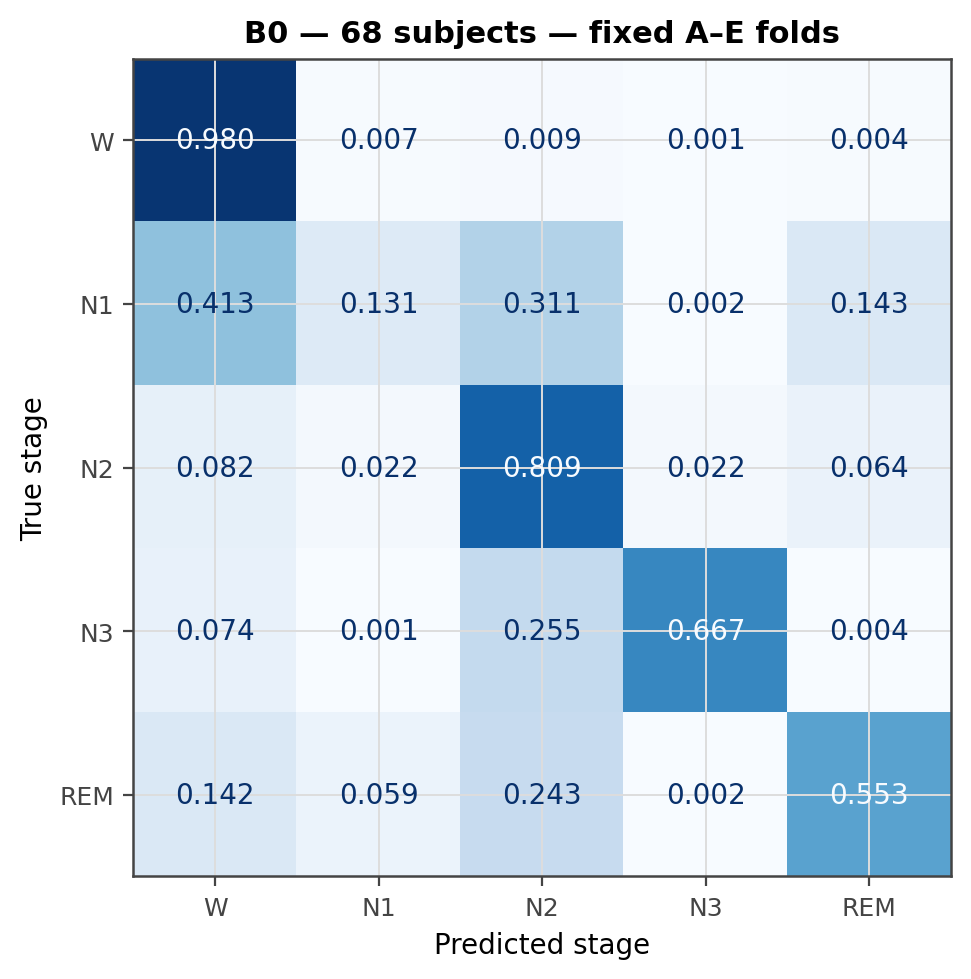


MATRIZ PARA COPIAR PARA O GOOGLE SHEETS
True / Predicted	W	N1	N2	N3	REM
W	0.9797	0.0065	0.0090	0.0007	0.0041
N1	0.4131	0.1308	0.3115	0.0021	0.1425
N2	0.0824	0.0224	0.8093	0.0222	0.0637
N3	0.0737	0.0005	0.2555	0.6667	0.0036
REM	0.1417	0.0593	0.2433	0.0022	0.5535



In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

estagios = ["W", "N1", "N2", "N3", "REM"]

# Colocar cada previsão na posição da sua época original.
previsoes_b0_68 = np.empty_like(y_b0_68)
fold_por_epoca_b0_68 = np.empty(len(y_b0_68), dtype="<U1")
cobertura_b0_68 = np.zeros(len(y_b0_68), dtype=np.uint8)

for fold, resultado in resultados_b0_68.items():
    indices = np.asarray(resultado["test_indices"], dtype=int)
    relatorio = resultado["report"]

    np.testing.assert_array_equal(
        indices, SPLITS_68[fold][1]
    )
    np.testing.assert_array_equal(
        relatorio["y_true"], y_b0_68[indices]
    )
    np.testing.assert_array_equal(
        relatorio["y_group"], groups_b0_68[indices]
    )

    assert len(relatorio["y_pred"]) == len(indices)
    assert np.all(cobertura_b0_68[indices] == 0)

    previsoes_b0_68[indices] = relatorio["y_pred"]
    fold_por_epoca_b0_68[indices] = fold
    cobertura_b0_68[indices] += 1

assert np.all(cobertura_b0_68 == 1)

# Relatório conjunto, incluindo resultados por fold e participante.
relatorio_b0_68 = track_b0_68._make_report(
    y_b0_68,
    previsoes_b0_68,
    groups=groups_b0_68,
    folds=fold_por_epoca_b0_68,
)

print("BASELINE — MÉTRICAS GLOBAIS")
for metrica in [
    "cohens_kappa", "macro_f1", "accuracy", "balanced_accuracy"
]:
    print(f"{metrica}: {relatorio_b0_68[metrica]:.3f}")

print("\nRESULTADOS POR ESTÁGIO")
print(classification_report(
    y_b0_68,
    previsoes_b0_68,
    labels=estagios,
    digits=3,
    zero_division=0,
))

# Matriz conjunta: cada linha soma 1.
cm_b0_68 = confusion_matrix(
    y_b0_68, previsoes_b0_68, labels=estagios
)
cm_b0_68_normalizada = (
    cm_b0_68 / cm_b0_68.sum(axis=1, keepdims=True)
)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(
    cm_b0_68_normalizada,
    display_labels=estagios,
).plot(
    ax=ax,
    cmap="Blues",
    values_format=".3f",
    colorbar=False,
    im_kw={"vmin": 0, "vmax": 1},
)

ax.set_title("B0 — 68 subjects — fixed A–E folds")
ax.set_xlabel("Predicted stage")
ax.set_ylabel("True stage")
plt.tight_layout()
plt.show()

# Valores para copiar para a folha da equipa.
tabela_cm_b0_68 = pd.DataFrame(
    cm_b0_68_normalizada,
    index=estagios,
    columns=estagios,
)
tabela_cm_b0_68.index.name = "True / Predicted"

print("\nMATRIZ PARA COPIAR PARA O GOOGLE SHEETS")
print(tabela_cm_b0_68.to_csv(
    sep="\t", float_format="%.4f"
))

In [ ]:
metricas = [
    "cohens_kappa", "macro_f1", "accuracy", "balanced_accuracy"
]

resumo_folds_b0_68 = {
    metrica: {
        "mean": tabela_b0_68[metrica].mean(),
        "std": tabela_b0_68[metrica].std(ddof=1),
        "n": 5,
        "ddof": 1,
    }
    for metrica in metricas
}

consolidado_b0_68 = {
    **meta_b0_68,
    "cv_method": "fixed_subject_5fold_AE",
    "preprocessing": "no additional filtering",
    "spectral_method": "welch",
    "training_crop": False,
    "evaluation_scope": "all original valid epochs, including Wake",
    "fold_metric_summary": resumo_folds_b0_68,
    "fit_seconds_total": sum(
        r["fit_seconds"] for r in resultados_b0_68.values()
    ),
    "report": relatorio_b0_68,
}

destino = EXPERIMENTS_DIR / "B0_68_fixed_AE.json"
temporario = destino.with_suffix(".tmp")

temporario.write_text(
    json.dumps(
        consolidado_b0_68,
        default=converter_numpy,
        indent=2,
    ),
    encoding="utf-8",
)
temporario.replace(destino)

imagem = EXPERIMENTS_DIR / "B0_68_fixed_AE_confusion.png"
fig.savefig(imagem, dpi=200, bbox_inches="tight")

print("Relatório guardado:", destino)
print("Imagem guardada:", imagem)

Relatório guardado: /content/drive/MyDrive/CM2013_data/experiments/B0_68_fixed_AE.json
Imagem guardada: /content/drive/MyDrive/CM2013_data/experiments/B0_68_fixed_AE_confusion.png


In [ ]:
F2_FEATURE_VERSION = 1

bandas_f2_68 = ["delta", "theta", "alpha", "sigma", "beta"]

indices_bandas_f2_68 = [
    nomes_features_b0.index(f"eeg_{banda}")
    for banda in bandas_f2_68
]

potencias = X_b0_68[:, indices_bandas_f2_68]

assert np.isfinite(potencias).all()
assert (potencias >= 0).all()

# Proporção de potência em cada uma das cinco bandas.
total = potencias.sum(axis=1, keepdims=True)

relativas = np.divide(
    potencias,
    total,
    out=np.zeros_like(potencias, dtype=float),
    where=total > 0,
)

# Manter as 11 características e acrescentar as cinco relativas.
X_f2_68 = np.column_stack([X_b0_68, relativas])

nomes_features_f2_68 = nomes_features_b0 + [
    f"eeg_{banda}_relative"
    for banda in bandas_f2_68
]

assert X_f2_68.shape == (len(y_b0_68), 16)
assert np.isfinite(X_f2_68).all()

print("Baseline:", X_b0_68.shape)
print("F2:", X_f2_68.shape)
print("F2 preparado para usar as mesmas labels e os mesmos folds A–E.")

Baseline: (360621, 11)
F2: (360621, 16)
F2 preparado para usar as mesmas labels e os mesmos folds A–E.


In [ ]:
from sklearn.base import clone

def avaliar_experiencia_68(
    nome, X, nomes_features, versao_features, detalhes=None
):
    assert X.shape == (len(y_b0_68), len(nomes_features))
    assert np.isfinite(X).all()

    modelo_base = clone(modelo_base_b0)

    meta = {
        **meta_b0_68,
        "experiment": nome,
        "feature_version": versao_features,
        "feature_names": list(nomes_features),
        "classifier_params": modelo_base.named_steps["clf"].get_params(),
        "scaler_params": modelo_base.named_steps["scale"].get_params(),
    }
    if detalhes is not None:
        meta["details"] = detalhes

    resultados = {}

    for fold in "ABCDE":
        treino, teste = SPLITS_68[fold]

        # Confirmar que estamos a comparar com o mesmo teste do B0.
        np.testing.assert_array_equal(
            teste,
            resultados_b0_68[fold]["test_indices"],
        )
        assert set(groups_b0_68[teste]) == set(FOLDS_68[fold])
        assert set(groups_b0_68[treino]).isdisjoint(
            set(groups_b0_68[teste])
        )

        destino = EXPERIMENTS_DIR / f"{nome}_fold_{fold}.json"

        if destino.exists():
            resultado = json.loads(
                destino.read_text(encoding="utf-8")
            )

            assert resultado["fold"] == fold
            for campo, valor in meta.items():
                assert resultado[campo] == valor, (
                    f"Fold {fold}: configuração diferente em {campo}."
                )

            np.testing.assert_array_equal(
                resultado["test_indices"], teste
            )
            np.testing.assert_array_equal(
                resultado["report"]["y_true"], y_b0_68[teste]
            )
            np.testing.assert_array_equal(
                resultado["report"]["y_group"], groups_b0_68[teste]
            )

            print(f"{nome} — fold {fold}: reutilizado.", flush=True)

        else:
            print(
                f"\n{nome} — fold {fold}: a treinar...",
                flush=True,
            )

            # Scaler e classificador novos em cada fold.
            modelo = clone(modelo_base)

            inicio = perf_counter()
            modelo.fit(X[treino], y_b0_68[treino])
            tempo_treino = perf_counter() - inicio

            inicio = perf_counter()
            previsoes = modelo.predict(X[teste])
            tempo_previsao = perf_counter() - inicio

            relatorio = track_b0_68._make_report(
                y_b0_68[teste],
                previsoes,
                groups=groups_b0_68[teste],
            )

            resultado = {
                **meta,
                "fold": fold,
                "training_subjects": sorted(set(groups_b0_68[treino])),
                "test_subjects": sorted(set(groups_b0_68[teste])),
                "test_indices": teste,
                "fit_seconds": tempo_treino,
                "predict_seconds": tempo_previsao,
                "report": relatorio,
            }

            temporario = destino.with_suffix(".tmp")
            temporario.write_text(
                json.dumps(
                    resultado,
                    default=converter_numpy,
                    indent=2,
                ),
                encoding="utf-8",
            )
            temporario.replace(destino)

            print(
                f"Fold {fold} concluído: "
                f"kappa = {relatorio['cohens_kappa']:.3f} | "
                f"treino = {tempo_treino / 60:.2f} min",
                flush=True,
            )

        resultados[fold] = resultado

    tabela = pd.DataFrame([
        {
            "Fold": fold,
            **{
                metrica: resultado["report"][metrica]
                for metrica in [
                    "cohens_kappa", "macro_f1",
                    "accuracy", "balanced_accuracy",
                ]
            },
            "Treino (min)": resultado["fit_seconds"] / 60,
        }
        for fold, resultado in resultados.items()
    ]).set_index("Fold")

    return resultados, tabela


# Avaliar F2.
resultados_f2_68, tabela_f2_68 = avaliar_experiencia_68(
    nome="F2_68_fixed_AE",
    X=X_f2_68,
    nomes_features=nomes_features_f2_68,
    versao_features=F2_FEATURE_VERSION,
    detalhes={
        "base_feature_version": B0_FEATURE_VERSION,
        "relative_bands": bandas_f2_68,
        "denominator": "sum of the five EEG band powers",
        "normalization_scope": "each epoch independently",
    },
)

print("\nF2 — CINCO FOLDS CONCLUÍDOS")
display(tabela_f2_68.round(3))

kappas_f2 = tabela_f2_68["cohens_kappa"]
print(
    f"Kappa médio ± SD entre os cinco folds: "
    f"{kappas_f2.mean():.3f} ± {kappas_f2.std(ddof=1):.3f}"
)

comparacao_b0_f2_68 = pd.DataFrame({
    "B0": tabela_b0_68["cohens_kappa"],
    "F2": tabela_f2_68["cohens_kappa"],
})
comparacao_b0_f2_68["Diferença"] = (
    comparacao_b0_f2_68["F2"] - comparacao_b0_f2_68["B0"]
)

print("\nCOMPARAÇÃO DO KAPPA NOS MESMOS FOLDS")
display(comparacao_b0_f2_68.round(3))


F2_68_fixed_AE — fold A: a treinar...
Fold A concluído: kappa = 0.753 | treino = 9.23 min

F2_68_fixed_AE — fold B: a treinar...
Fold B concluído: kappa = 0.718 | treino = 9.08 min

F2_68_fixed_AE — fold C: a treinar...
Fold C concluído: kappa = 0.739 | treino = 9.25 min

F2_68_fixed_AE — fold D: a treinar...
Fold D concluído: kappa = 0.717 | treino = 9.35 min

F2_68_fixed_AE — fold E: a treinar...
Fold E concluído: kappa = 0.748 | treino = 9.36 min

F2 — CINCO FOLDS CONCLUÍDOS


,cohens_kappa,macro_f1,accuracy,balanced_accuracy,Treino (min)
Fold,,,,,
A,0.753,0.679,0.885,0.676,9.232
B,0.718,0.647,0.862,0.636,9.083
C,0.739,0.652,0.878,0.622,9.248
D,0.717,0.638,0.875,0.598,9.350
E,0.748,0.673,0.879,0.653,9.364


Kappa médio ± SD entre os cinco folds: 0.735 ± 0.017

COMPARAÇÃO DO KAPPA NOS MESMOS FOLDS


,B0,F2,Diferença
Fold,,,
A,0.743,0.753,0.010
B,0.716,0.718,0.002
C,0.730,0.739,0.009
D,0.715,0.717,0.002
E,0.737,0.748,0.011


F2 — MÉTRICAS GLOBAIS
cohens_kappa: 0.735
macro_f1: 0.659
accuracy: 0.876
balanced_accuracy: 0.638

F2 — RESULTADOS POR ESTÁGIO
              precision    recall  f1-score   support

           W      0.939     0.980     0.959    248341
          N1      0.351     0.135     0.195     17877
          N2      0.761     0.813     0.786     60494
          N3      0.838     0.681     0.751     11610
         REM      0.631     0.581     0.605     22299

    accuracy                          0.876    360621
   macro avg      0.704     0.638     0.659    360621
weighted avg      0.857     0.876     0.863    360621


COMPARAÇÃO POR ESTÁGIO


,Recall B0,Recall F2,F1 B0,F1 F2,Diferença F1
Estágio,,,,,
W,0.980,0.980,0.958,0.959,0.001
N1,0.131,0.135,0.191,0.195,0.004
N2,0.809,0.813,0.779,0.786,0.007
N3,0.667,0.681,0.739,0.751,0.012
REM,0.553,0.581,0.586,0.605,0.019


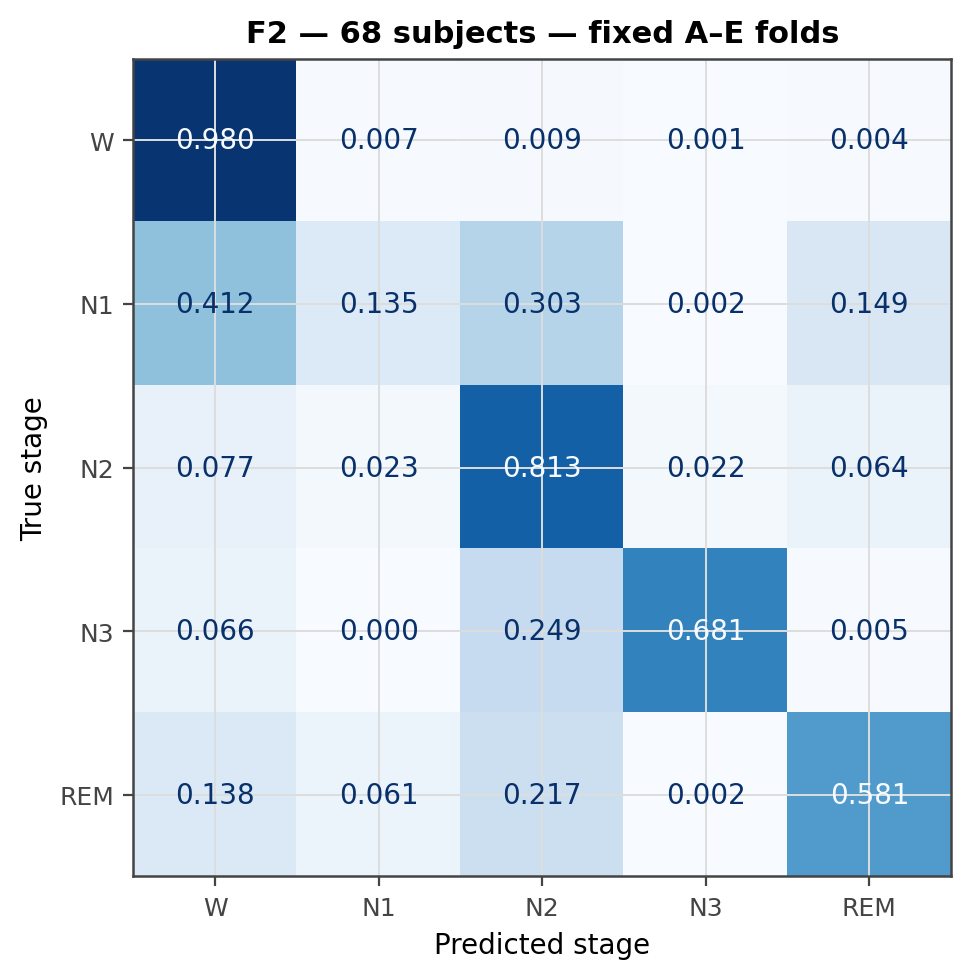

In [ ]:
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
)

# Função reutilizável para juntar as previsões dos cinco folds.
def juntar_previsoes_68(resultados):
    assert set(resultados) == set("ABCDE")

    previsoes = np.empty_like(y_b0_68)
    folds = np.empty(len(y_b0_68), dtype="<U1")
    cobertura = np.zeros(len(y_b0_68), dtype=np.uint8)

    for fold, resultado in resultados.items():
        indices = np.asarray(resultado["test_indices"], dtype=int)
        relatorio = resultado["report"]

        np.testing.assert_array_equal(
            indices, SPLITS_68[fold][1]
        )
        np.testing.assert_array_equal(
            relatorio["y_true"], y_b0_68[indices]
        )
        np.testing.assert_array_equal(
            relatorio["y_group"], groups_b0_68[indices]
        )

        assert len(relatorio["y_pred"]) == len(indices)
        assert np.all(cobertura[indices] == 0)

        previsoes[indices] = relatorio["y_pred"]
        folds[indices] = fold
        cobertura[indices] += 1

    assert np.all(cobertura == 1)

    relatorio = track_b0_68._make_report(
        y_b0_68,
        previsoes,
        groups=groups_b0_68,
        folds=folds,
    )

    return previsoes, relatorio


previsoes_f2_68, relatorio_f2_68 = juntar_previsoes_68(
    resultados_f2_68
)

estagios = ["W", "N1", "N2", "N3", "REM"]

print("F2 — MÉTRICAS GLOBAIS")
for metrica in [
    "cohens_kappa", "macro_f1", "accuracy", "balanced_accuracy"
]:
    print(f"{metrica}: {relatorio_f2_68[metrica]:.3f}")

print("\nF2 — RESULTADOS POR ESTÁGIO")
print(classification_report(
    y_b0_68,
    previsoes_f2_68,
    labels=estagios,
    digits=3,
    zero_division=0,
))

# Comparação direta com o baseline.
classes_b0 = classification_report(
    y_b0_68, previsoes_b0_68,
    labels=estagios, output_dict=True, zero_division=0,
)
classes_f2 = classification_report(
    y_b0_68, previsoes_f2_68,
    labels=estagios, output_dict=True, zero_division=0,
)

comparacao_estagios_b0_f2_68 = pd.DataFrame([
    {
        "Estágio": estagio,
        "Recall B0": classes_b0[estagio]["recall"],
        "Recall F2": classes_f2[estagio]["recall"],
        "F1 B0": classes_b0[estagio]["f1-score"],
        "F1 F2": classes_f2[estagio]["f1-score"],
        "Diferença F1": (
            classes_f2[estagio]["f1-score"]
            - classes_b0[estagio]["f1-score"]
        ),
    }
    for estagio in estagios
]).set_index("Estágio")

print("\nCOMPARAÇÃO POR ESTÁGIO")
display(comparacao_estagios_b0_f2_68.round(3))

# Matriz de confusão com a mesma escala usada no baseline.
fig_f2_68, ax_f2_68 = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_b0_68,
    previsoes_f2_68,
    labels=estagios,
    normalize="true",
    values_format=".3f",
    cmap="Blues",
    colorbar=False,
    im_kw={"vmin": 0, "vmax": 1},
    ax=ax_f2_68,
)

ax_f2_68.set_title("F2 — 68 subjects — fixed A–E folds")
ax_f2_68.set_xlabel("Predicted stage")
ax_f2_68.set_ylabel("True stage")
plt.tight_layout()
plt.show()

In [ ]:
# Separar a informação comum da informação específica do fold A.
campos_do_fold = {
    "fold", "training_subjects", "test_subjects",
    "test_indices", "fit_seconds", "predict_seconds", "report",
}

meta_f2_68 = {
    campo: valor
    for campo, valor in resultados_f2_68["A"].items()
    if campo not in campos_do_fold
}

consolidado_f2_68 = {
    **meta_f2_68,
    "cv_method": "fixed_subject_5fold_AE",
    "preprocessing": "no additional filtering",
    "spectral_method": "welch",
    "training_crop": False,
    "evaluation_scope": "all original valid epochs, including Wake",
    "fold_metric_summary": {
        metrica: {
            "mean": tabela_f2_68[metrica].mean(),
            "std": tabela_f2_68[metrica].std(ddof=1),
            "n": 5,
            "ddof": 1,
        }
        for metrica in [
            "cohens_kappa", "macro_f1",
            "accuracy", "balanced_accuracy",
        ]
    },
    "fit_seconds_total": sum(
        r["fit_seconds"] for r in resultados_f2_68.values()
    ),
    "report": relatorio_f2_68,
}

destino_f2 = EXPERIMENTS_DIR / "F2_68_fixed_AE.json"
temporario_f2 = destino_f2.with_suffix(".tmp")

temporario_f2.write_text(
    json.dumps(
        consolidado_f2_68,
        default=converter_numpy,
        indent=2,
    ),
    encoding="utf-8",
)
temporario_f2.replace(destino_f2)

imagem_f2 = EXPERIMENTS_DIR / "F2_68_fixed_AE_confusion.png"
fig_f2_68.savefig(imagem_f2, dpi=200, bbox_inches="tight")

print("Relatório guardado:", destino_f2)
print("Imagem guardada:", imagem_f2)

Relatório guardado: /content/drive/MyDrive/CM2013_data/experiments/F2_68_fixed_AE.json
Imagem guardada: /content/drive/MyDrive/CM2013_data/experiments/F2_68_fixed_AE_confusion.png


In [ ]:
# Resultados individuais dos 68 participantes.
scores_inspecao = pd.DataFrame(
    relatorio_f2_68["per_group"]
)[["group", "cohens_kappa"]]

scores_inspecao = (
    scores_inspecao
    .dropna(subset=["cohens_kappa"])
    .sort_values(["cohens_kappa", "group"])
    .reset_index(drop=True)
)

assert len(scores_inspecao) >= 3

selecoes = [
    ("Kappa mais baixo", 0),
    ("Kappa intermédio", len(scores_inspecao) // 2),
    ("Kappa mais alto", len(scores_inspecao) - 1),
]

plano_inspecao_68 = []

for perfil, posicao in selecoes:
    linha = scores_inspecao.iloc[posicao]
    participante = str(linha["group"])

    # Escolher a primeira gravação disponível dessa pessoa.
    gravacoes = sorted(
        [
            dados for dados in b0_gravacoes_68
            if dados["record"][:5] == participante
        ],
        key=lambda dados: dados["record"],
    )

    assert gravacoes
    dados = gravacoes[0]

    plano_inspecao_68.append({
        "Perfil": perfil,
        "Participante": participante,
        "Kappa F2": float(linha["cohens_kappa"]),
        "Gravação": dados["record"],
        "Épocas": len(dados["y"]),
        "Épocas N1": int(np.count_nonzero(dados["y"] == "N1")),
    })

display(pd.DataFrame(plano_inspecao_68).round(3))

,Perfil,Participante,Kappa F2,Gravação,Épocas,Épocas N1
0,Kappa mais baixo,SC461,0.241,SC4611E0,2644,123
1,Kappa intermédio,SC453,0.763,SC4531E0,2602,124
2,Kappa mais alto,SC414,0.905,SC4141E0,2756,29


Gravação: SC4611E0 | Épocas: 2644
Épocas com NaN/Inf: 0
Épocas completamente constantes: 0


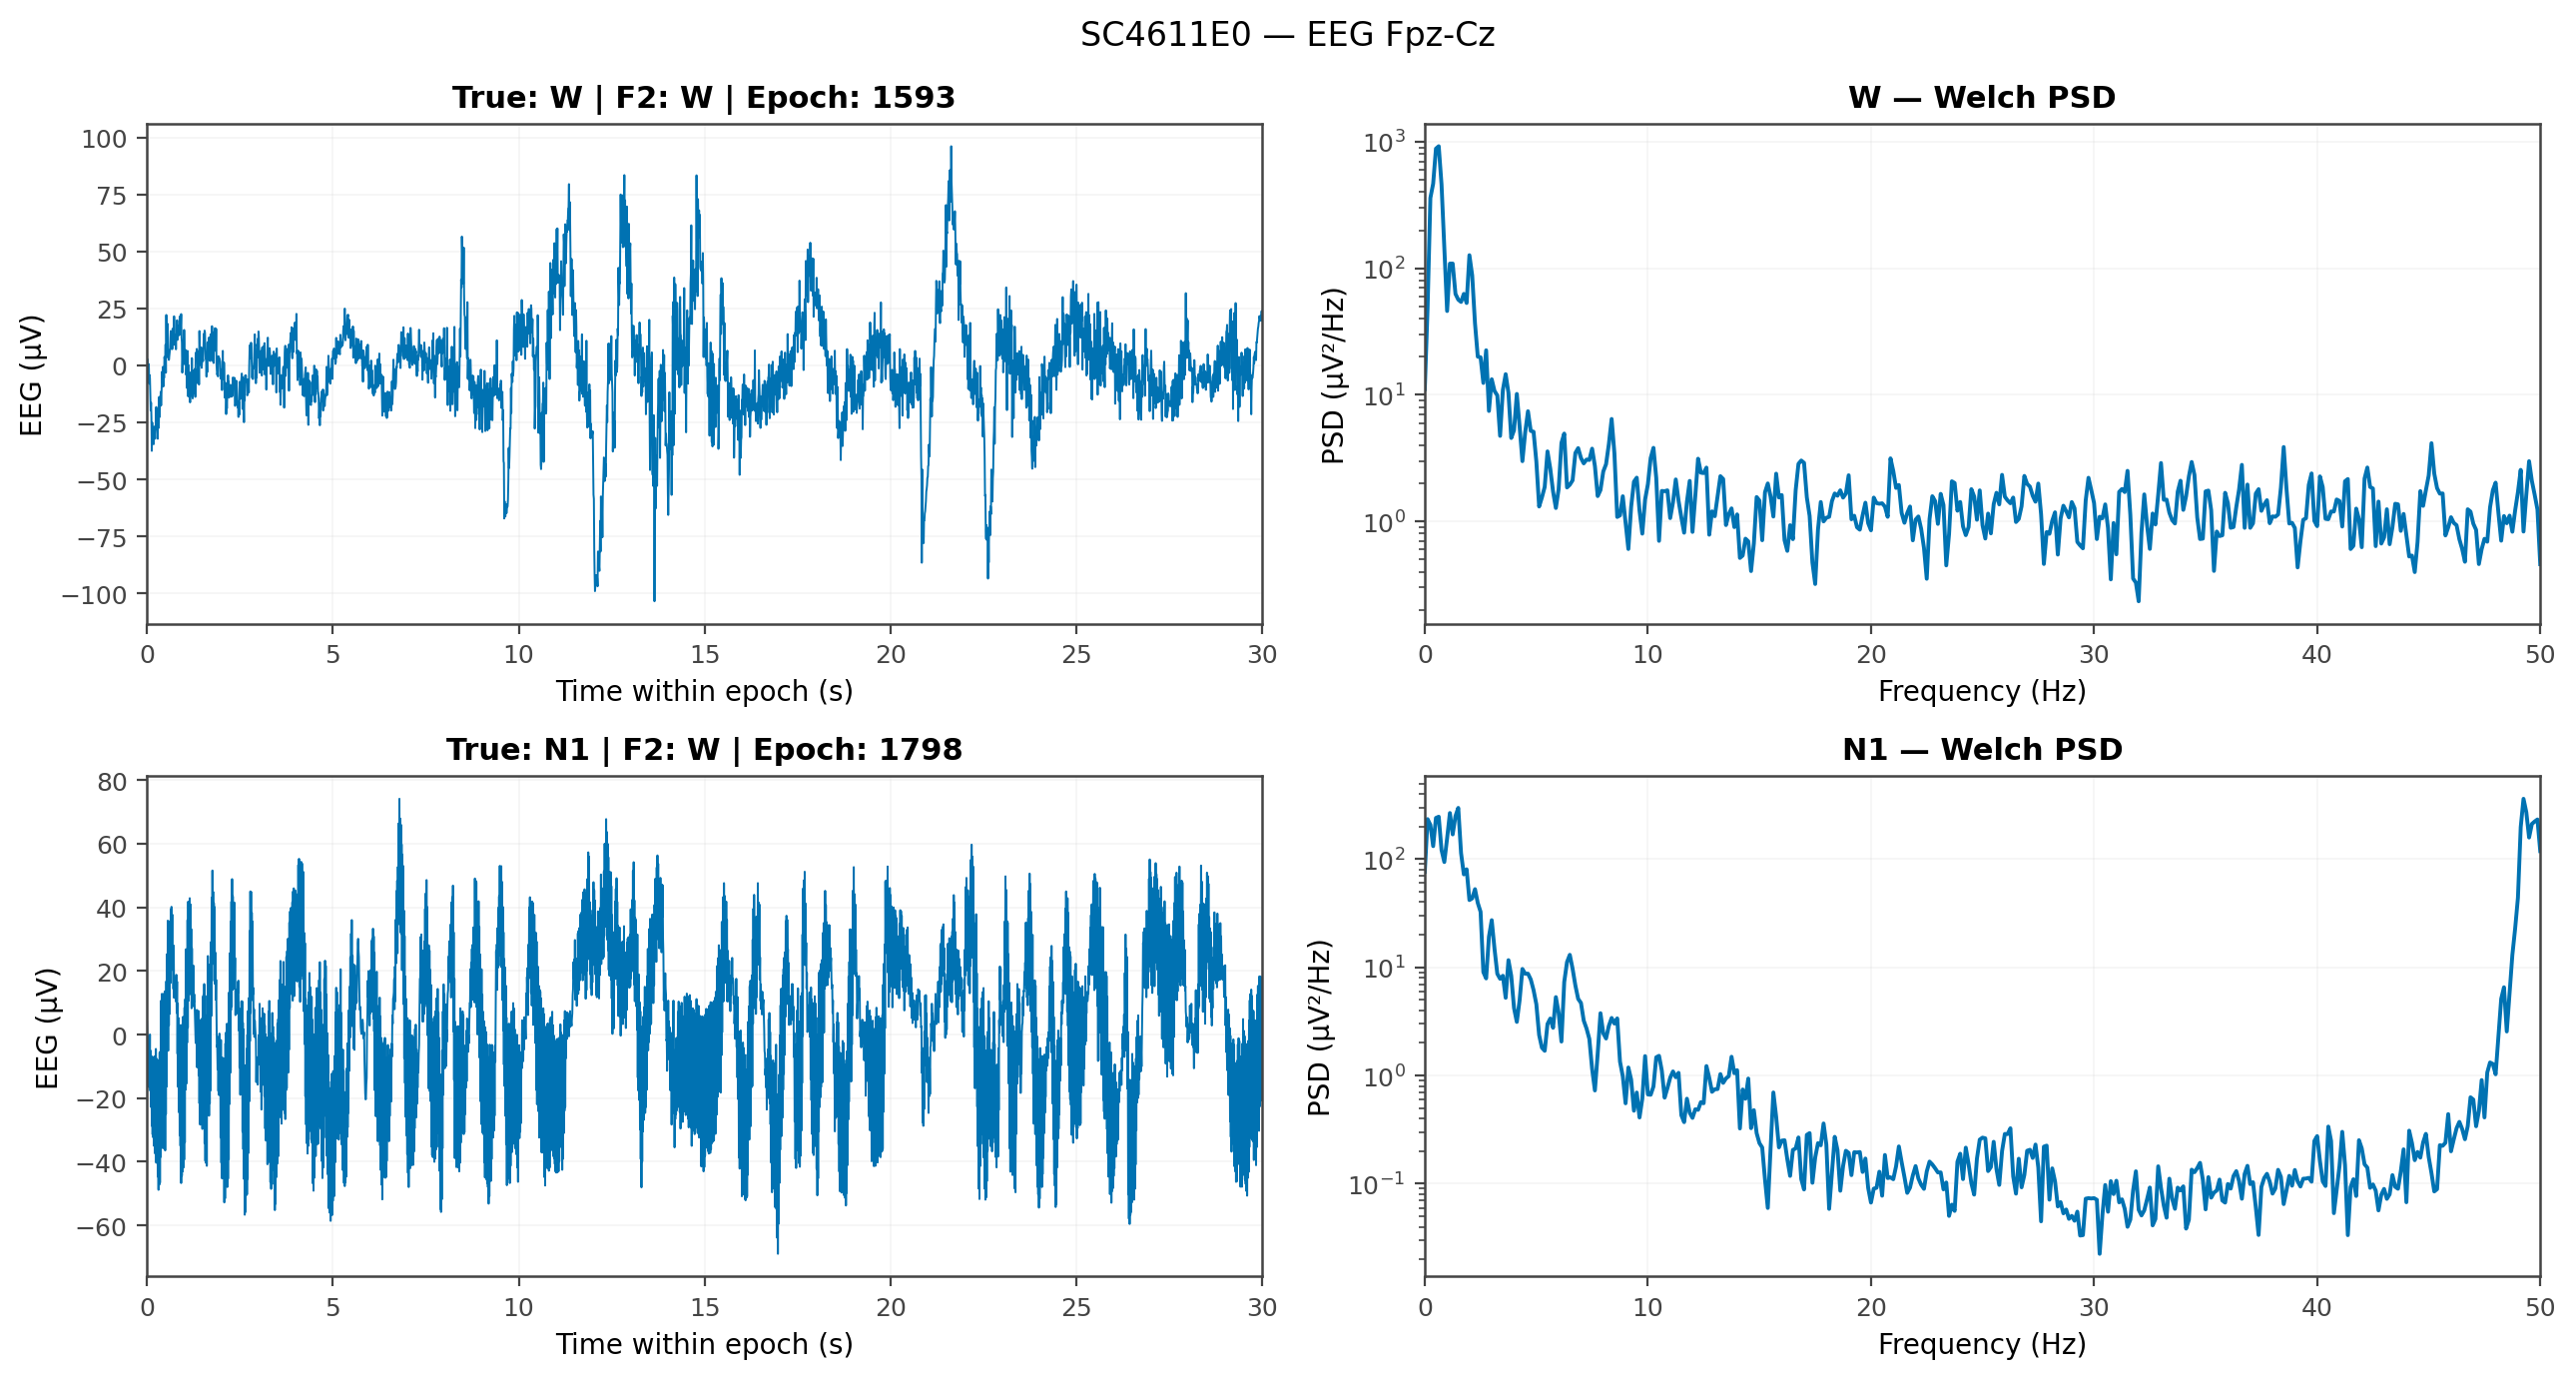

,Estágio real,Época retida,Previsão F2,Pico-a-pico (µV)
0,W,1593,W,199.789
1,N1,1798,W,143.024


In [ ]:
from pathlib import Path
from tempfile import TemporaryDirectory
from scipy.signal import welch

def carregar_gravacao_inspecao_68(record_id):
    assert record_id[:5] in DEVELOPMENT_GROUPS_68

    ficheiros = list(TRAIN_DIR.rglob(f"{record_id}-PSG.edf"))
    assert len(ficheiros) == 1
    psg = ficheiros[0]

    marcacoes = list(
        psg.parent.glob(f"{record_id[:6]}*-Hypnogram.edf")
    )
    assert len(marcacoes) == 1

    # Ler apenas este par de ficheiros, através de ligações locais.
    with TemporaryDirectory() as pasta:
        for origem in (psg, marcacoes[0]):
            (Path(pasta) / origem.name).symlink_to(origem.resolve())

        gravacoes = track_b0_68.load(
            pasta, fs_target=100.0, epoch_s=30.0
        )

    assert len(gravacoes) == 1
    return gravacoes[0]


record_id_inspecao = plano_inspecao_68[0]["Gravação"]

# Reutilizar a gravação na memória se repetirmos esta célula.
if (
    "rec_inspecao_68" not in globals()
    or rec_inspecao_68.meta["record"] != record_id_inspecao
):
    rec_inspecao_68 = carregar_gravacao_inspecao_68(
        record_id_inspecao
    )

rec = rec_inspecao_68
fs = float(rec.fs)
eeg_uv = np.asarray(rec.epochs["eeg"]) * 1e6

# Confirmar alinhamento com as previsões já feitas pelo F2.
indices_gravacao = np.flatnonzero(
    record_ids_b0_68 == record_id_inspecao
)
np.testing.assert_array_equal(
    rec.labels, y_b0_68[indices_gravacao]
)
previsoes_gravacao = previsoes_f2_68[indices_gravacao]

finitas = np.isfinite(eeg_uv).all(axis=1)
print(f"Gravação: {record_id_inspecao} | Épocas: {len(rec.labels)}")
print("Épocas com NaN/Inf:", int((~finitas).sum()))
assert finitas.all(), "Verificar valores inválidos antes dos gráficos."

amplitudes = np.ptp(eeg_uv, axis=1)
print("Épocas completamente constantes:", int((amplitudes == 0).sum()))

fig_inspecao_68, axes = plt.subplots(2, 2, figsize=(13, 7))
exemplos_inspecao_68 = []

for linha, estagio in enumerate(["W", "N1"]):
    candidatos = np.flatnonzero(rec.labels == estagio)
    assert len(candidatos) > 0

    # Época mais próxima da mediana pico-a-pico deste estágio.
    mediana = np.median(amplitudes[candidatos])
    i = candidatos[
        np.argmin(np.abs(amplitudes[candidatos] - mediana))
    ]

    sinal = eeg_uv[i]
    tempo = np.arange(len(sinal)) / fs

    axes[linha, 0].plot(tempo, sinal, linewidth=0.7)
    axes[linha, 0].set(
        title=f"True: {estagio} | F2: {previsoes_gravacao[i]} | Epoch: {i}",
        xlabel="Time within epoch (s)",
        ylabel="EEG (µV)",
        xlim=(0, len(sinal) / fs),
    )

    # Estas definições são apenas para o gráfico de inspeção.
    nperseg = min(int(8 * fs), len(sinal))
    frequencias, psd = welch(
        sinal, fs=fs, window="hann",
        nperseg=nperseg, noverlap=nperseg // 2,
        detrend="constant", scaling="density",
    )

    positivos = psd > 0
    axes[linha, 1].semilogy(
        frequencias[positivos], psd[positivos]
    )
    axes[linha, 1].set(
        title=f"{estagio} — Welch PSD",
        xlabel="Frequency (Hz)",
        ylabel="PSD (µV²/Hz)",
        xlim=(0, fs / 2),
    )

    for ax in axes[linha]:
        ax.grid(True, alpha=0.25)

    exemplos_inspecao_68.append({
        "Estágio real": estagio,
        "Época retida": int(i),
        "Previsão F2": str(previsoes_gravacao[i]),
        "Pico-a-pico (µV)": float(amplitudes[i]),
    })

fig_inspecao_68.suptitle(f"{record_id_inspecao} — EEG Fpz-Cz")
fig_inspecao_68.tight_layout()
plt.show()

display(pd.DataFrame(exemplos_inspecao_68).round(3))

Percentagem da potência de 0,5–50 Hz situada em 48–50 Hz:


,Épocas,Mediana 48–50 Hz (%),P95 48–50 Hz (%)
Estágio,,,
W,1707,1.06,16.68
N1,123,48.47,90.68
N2,276,44.61,88.43
N3,139,29.54,80.43
REM,399,49.45,63.34


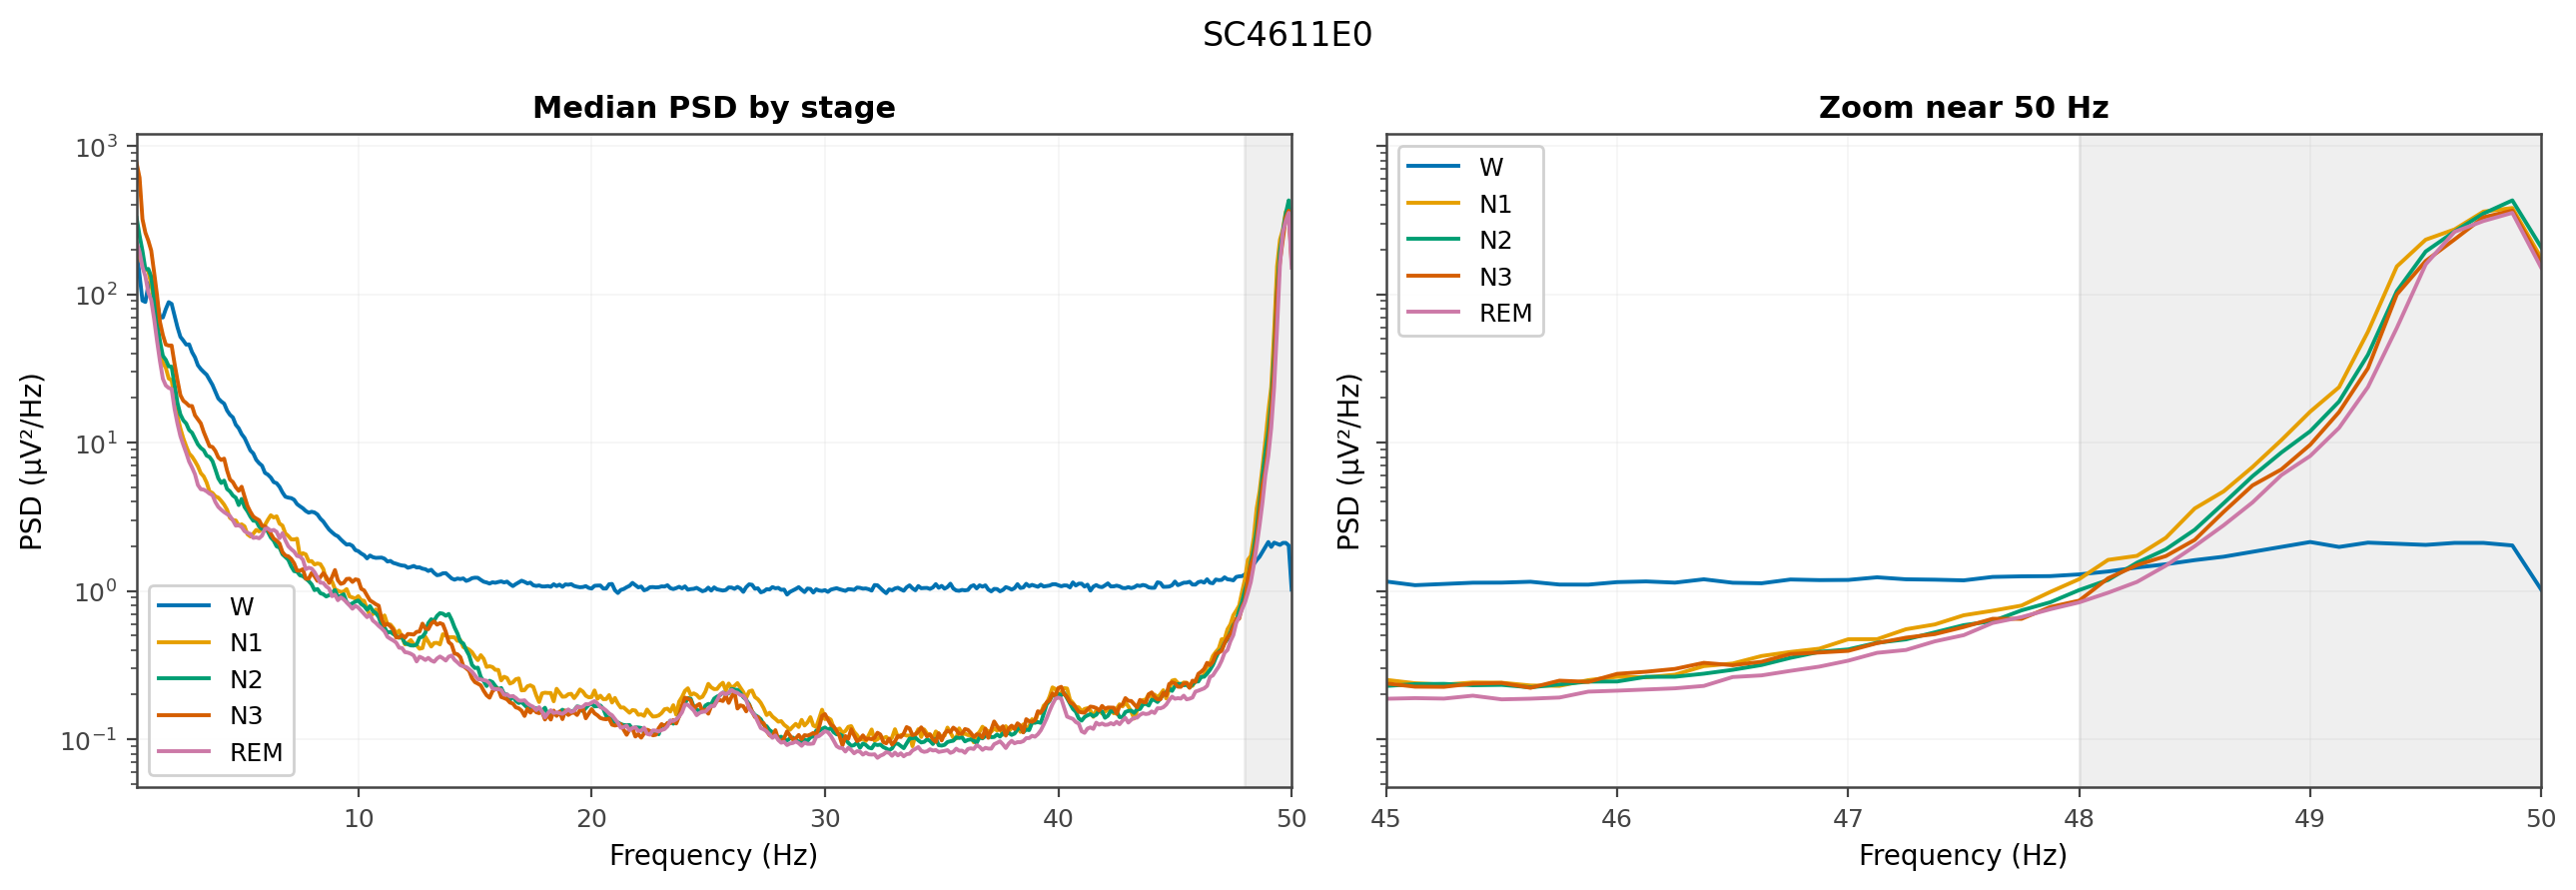

In [ ]:
def resumir_espectros_68(rec):
    fs = float(rec.fs)
    assert np.isclose(fs, 100.0)

    eeg = np.asarray(rec.epochs["eeg"]) * 1e6
    assert np.isfinite(eeg).all()

    nperseg = min(int(8 * fs), eeg.shape[1])

    # Um PSD por época, sem juntar épocas descontínuas.
    frequencias, psds = welch(
        eeg,
        fs=fs,
        window="hann",
        nperseg=nperseg,
        noverlap=nperseg // 2,
        detrend="constant",
        scaling="density",
        axis=-1,
    )

    banda_total = (frequencias >= 0.5) & (frequencias <= 50)
    banda_alta = (frequencias >= 48) & (frequencias <= 50)

    potencia_total = np.trapezoid(
        psds[:, banda_total],
        frequencias[banda_total],
        axis=1,
    )
    potencia_alta = np.trapezoid(
        psds[:, banda_alta],
        frequencias[banda_alta],
        axis=1,
    )

    percentagem_alta = 100 * np.divide(
        potencia_alta,
        potencia_total,
        out=np.full_like(potencia_total, np.nan),
        where=potencia_total > 0,
    )

    linhas = []
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

    for estagio in ["W", "N1", "N2", "N3", "REM"]:
        mascara = rec.labels == estagio
        valores = percentagem_alta[mascara]
        valores = valores[np.isfinite(valores)]

        linhas.append({
            "Estágio": estagio,
            "Épocas": int(mascara.sum()),
            "Mediana 48–50 Hz (%)": (
                float(np.median(valores)) if len(valores) else np.nan
            ),
            "P95 48–50 Hz (%)": (
                float(np.percentile(valores, 95))
                if len(valores) else np.nan
            ),
        })

        if not mascara.any():
            continue

        # Mediana dos PSDs em cada frequência, para este estágio.
        mediana_psd = np.median(psds[mascara], axis=0)
        visiveis = banda_total & (mediana_psd > 0)

        for ax in axes:
            ax.semilogy(
                frequencias[visiveis],
                mediana_psd[visiveis],
                label=estagio,
            )

    axes[0].set(title="Median PSD by stage", xlim=(0.5, 50))
    axes[1].set(title="Zoom near 50 Hz", xlim=(45, 50))

    for ax in axes:
        ax.set_xlabel("Frequency (Hz)")
        ax.set_ylabel("PSD (µV²/Hz)")
        ax.axvspan(48, 50, color="grey", alpha=0.12)
        ax.grid(True, alpha=0.25)
        ax.legend()

    fig.suptitle(rec.meta["record"])
    fig.tight_layout()

    return pd.DataFrame(linhas).set_index("Estágio"), fig


tabela_espectral_68, fig_espectral_68 = resumir_espectros_68(
    rec_inspecao_68
)

print("Percentagem da potência de 0,5–50 Hz situada em 48–50 Hz:")
display(tabela_espectral_68.round(2))
plt.show()


Kappa intermédio | SC453 | Gravação: SC4531E0


,Épocas,Mediana 48–50 Hz (%),P95 48–50 Hz (%)
Estágio,,,
W,1748,1.69,4.57
N1,124,2.57,9.36
N2,465,1.05,5.45
N3,85,1.56,3.33
REM,180,1.59,13.41


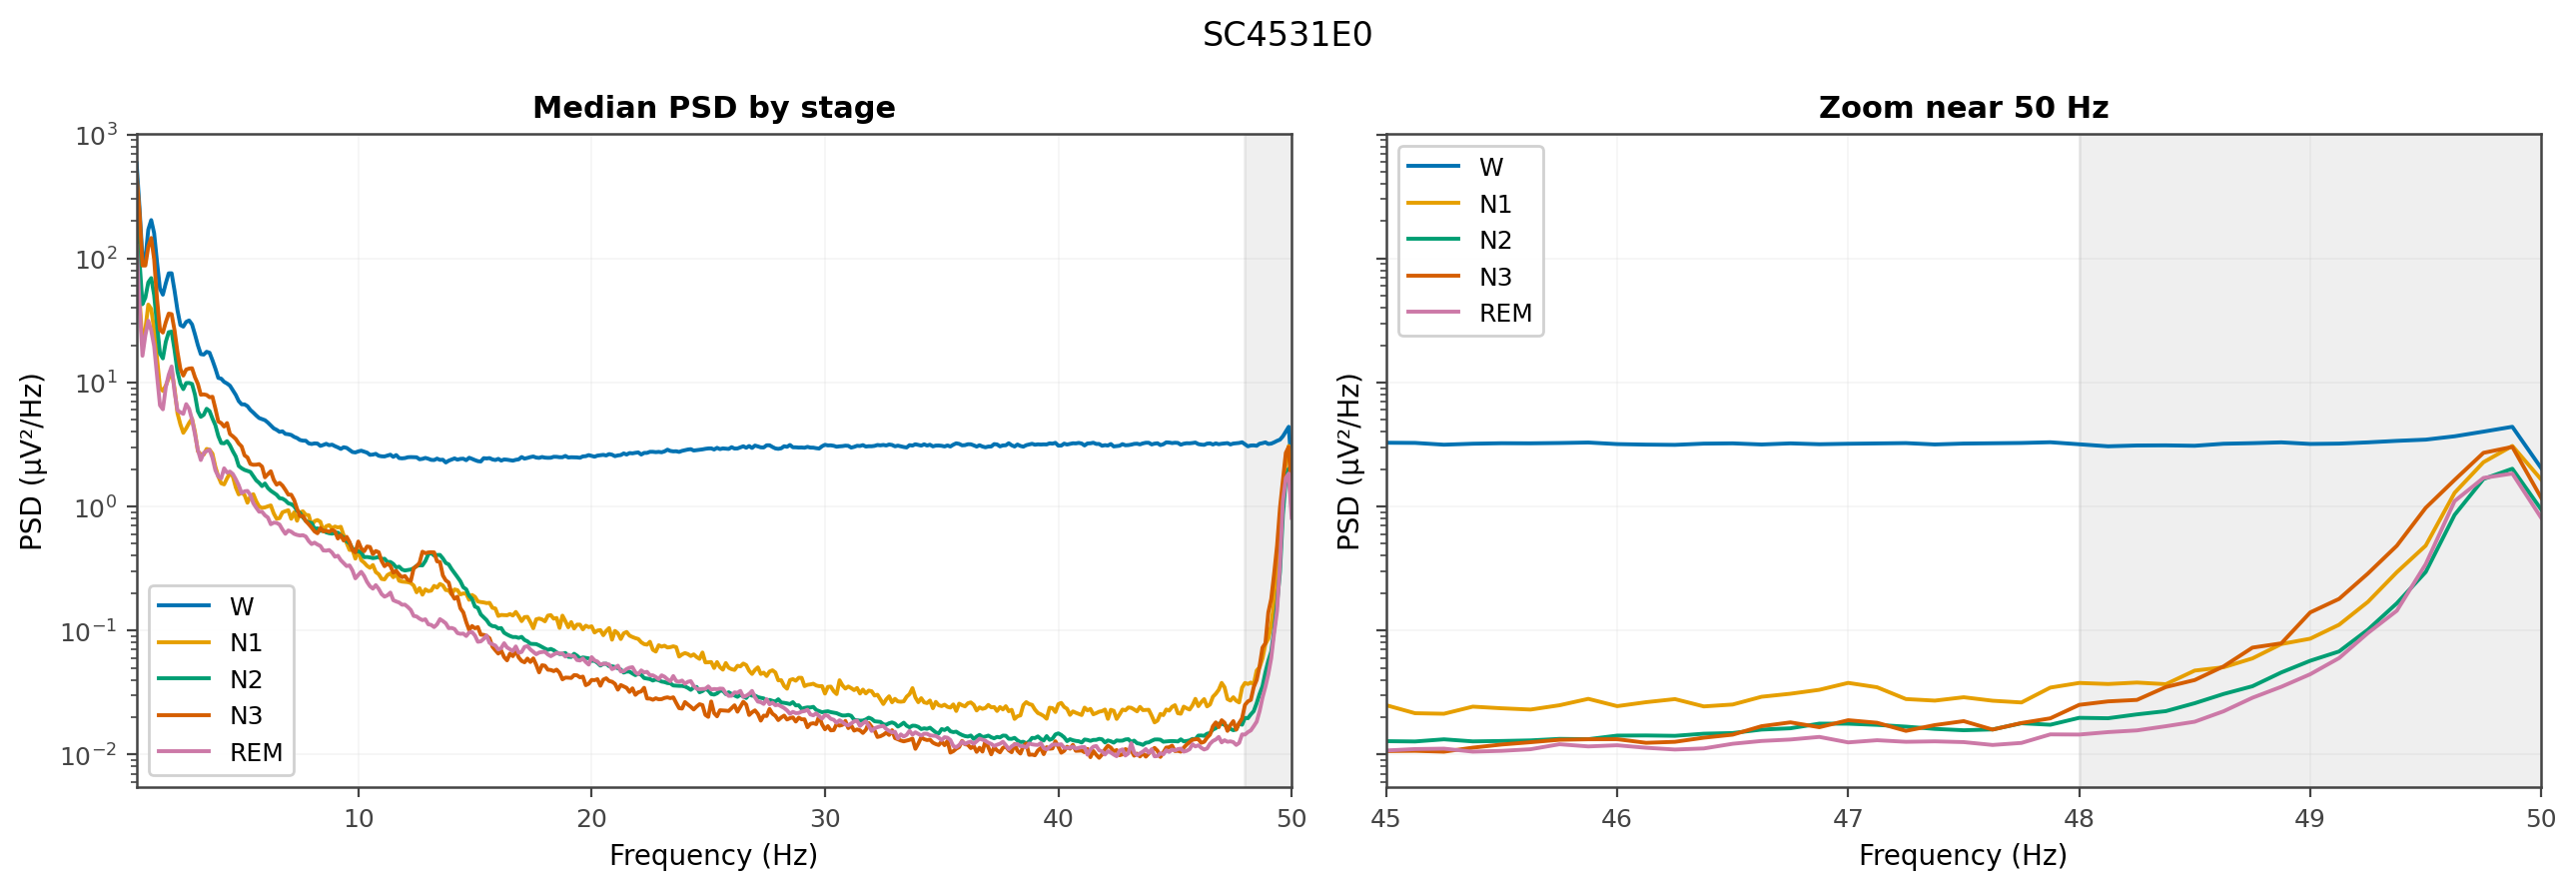


Kappa mais alto | SC414 | Gravação: SC4141E0


,Épocas,Mediana 48–50 Hz (%),P95 48–50 Hz (%)
Estágio,,,
W,1939,0.87,3.22
N1,29,0.50,1.00
N2,404,0.11,0.42
N3,151,0.04,0.10
REM,233,0.27,0.59


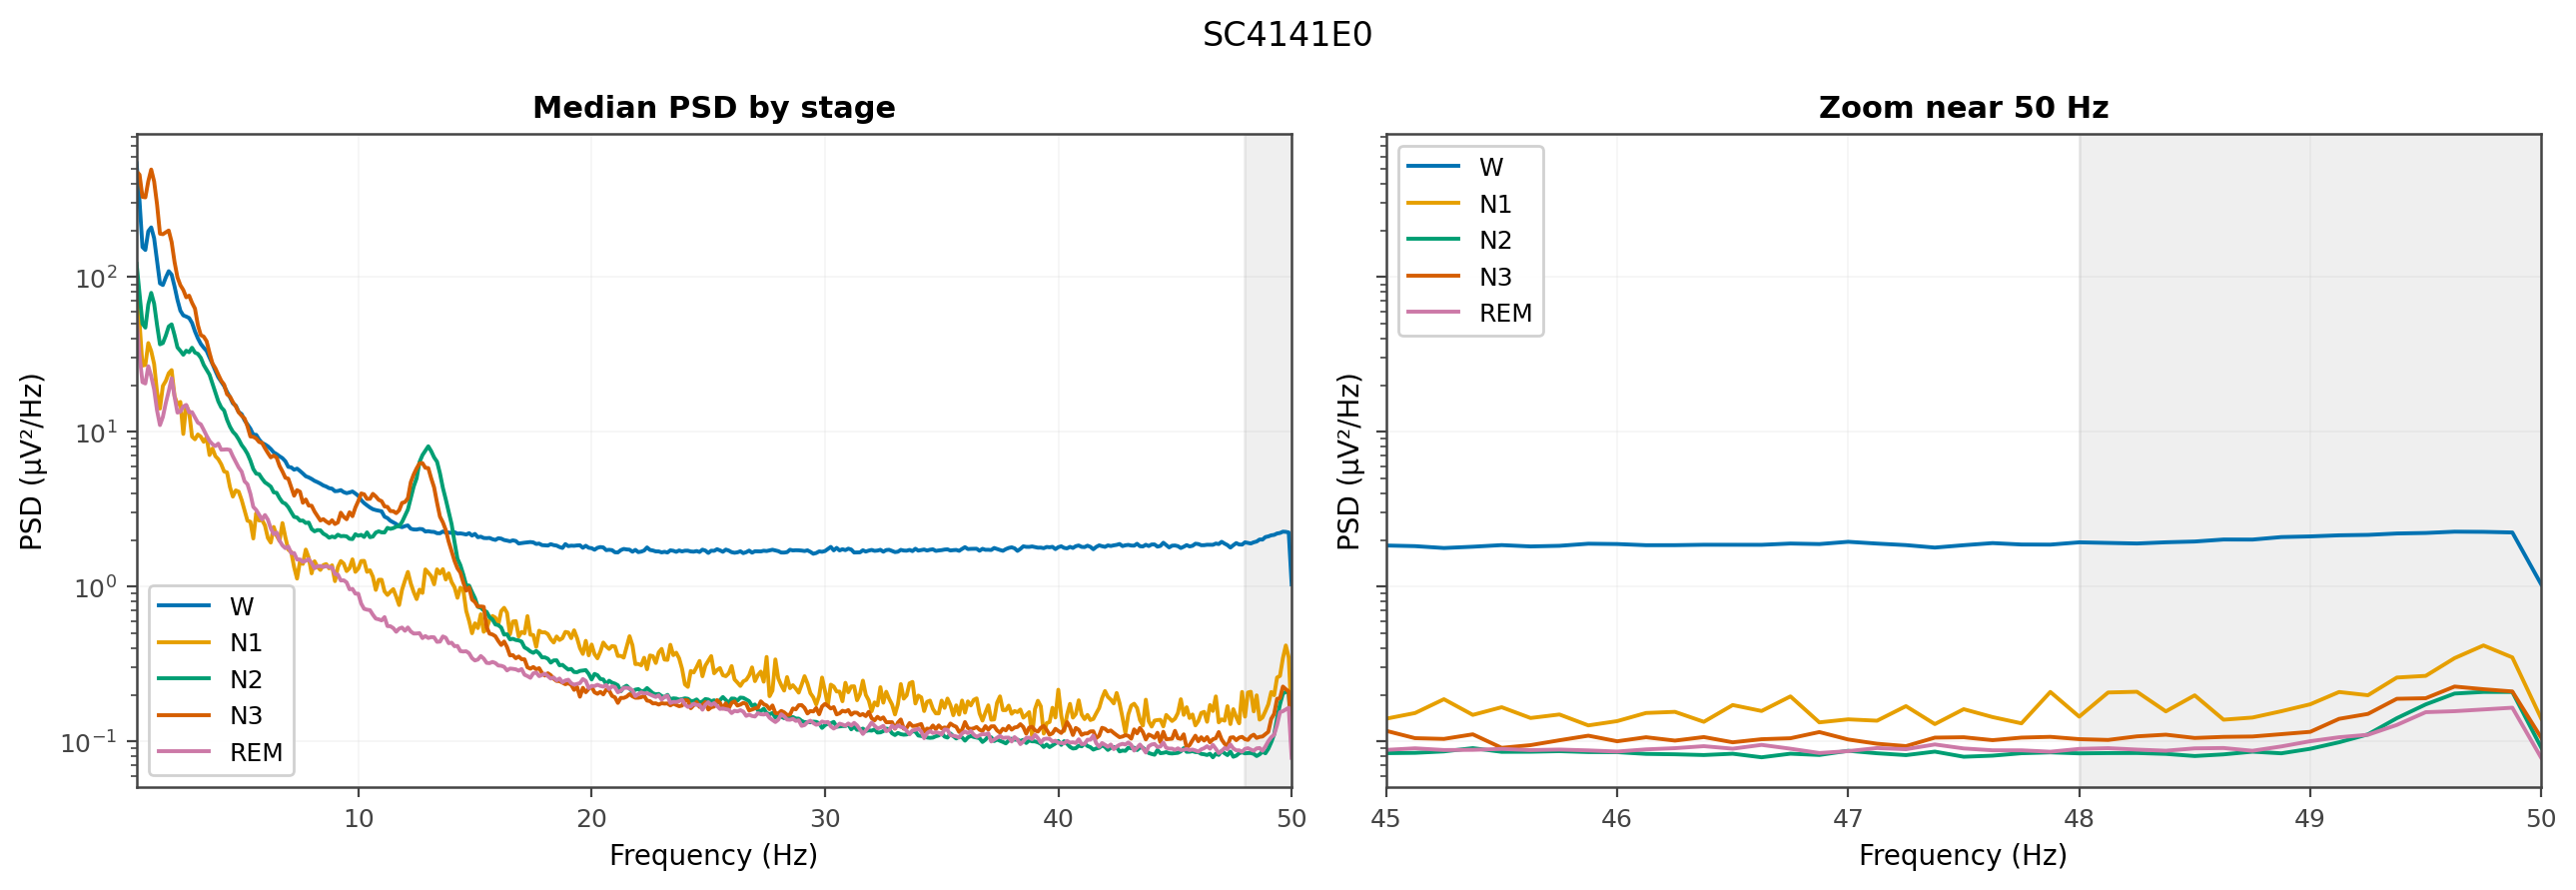


COMPARAÇÃO DAS TRÊS GRAVAÇÕES


,Gravação,Estágio,Épocas,Mediana 48–50 Hz (%),P95 48–50 Hz (%)
0,SC4611E0,W,1707,1.06,16.68
1,SC4611E0,N1,123,48.47,90.68
2,SC4611E0,N2,276,44.61,88.43
3,SC4611E0,N3,139,29.54,80.43
4,SC4611E0,REM,399,49.45,63.34
5,SC4531E0,W,1748,1.69,4.57
6,SC4531E0,N1,124,2.57,9.36
7,SC4531E0,N2,465,1.05,5.45
8,SC4531E0,N3,85,1.56,3.33
9,SC4531E0,REM,180,1.59,13.41


In [ ]:
# Preservar o diagnóstico de SC4611E0.
primeira_gravacao = plano_inspecao_68[0]["Gravação"]

tabelas_espectrais_68 = {
    primeira_gravacao: tabela_espectral_68.copy()
}

figuras_espectrais_68 = {
    primeira_gravacao: fig_espectral_68
}

# Inspecionar os participantes com kappa intermédio e alto.
for selecao in plano_inspecao_68[1:]:
    record_id = selecao["Gravação"]

    print(
        f"\n{selecao['Perfil']} | "
        f"{selecao['Participante']} | "
        f"Gravação: {record_id}",
        flush=True,
    )

    rec_diagnostico = carregar_gravacao_inspecao_68(record_id)

    # Confirmar as mesmas épocas usadas na avaliação.
    indices = np.flatnonzero(record_ids_b0_68 == record_id)
    np.testing.assert_array_equal(
        rec_diagnostico.labels,
        y_b0_68[indices],
    )

    tabela_atual, figura_atual = resumir_espectros_68(
        rec_diagnostico
    )

    tabelas_espectrais_68[record_id] = tabela_atual.copy()
    figuras_espectrais_68[record_id] = figura_atual

    display(tabela_atual.round(2))
    plt.show()

    del rec_diagnostico

# Comparação das três gravações.
comparacao_espectral_68 = pd.concat(
    tabelas_espectrais_68,
    names=["Gravação", "Estágio"],
).reset_index()

print("\nCOMPARAÇÃO DAS TRÊS GRAVAÇÕES")
display(comparacao_espectral_68.round(2))

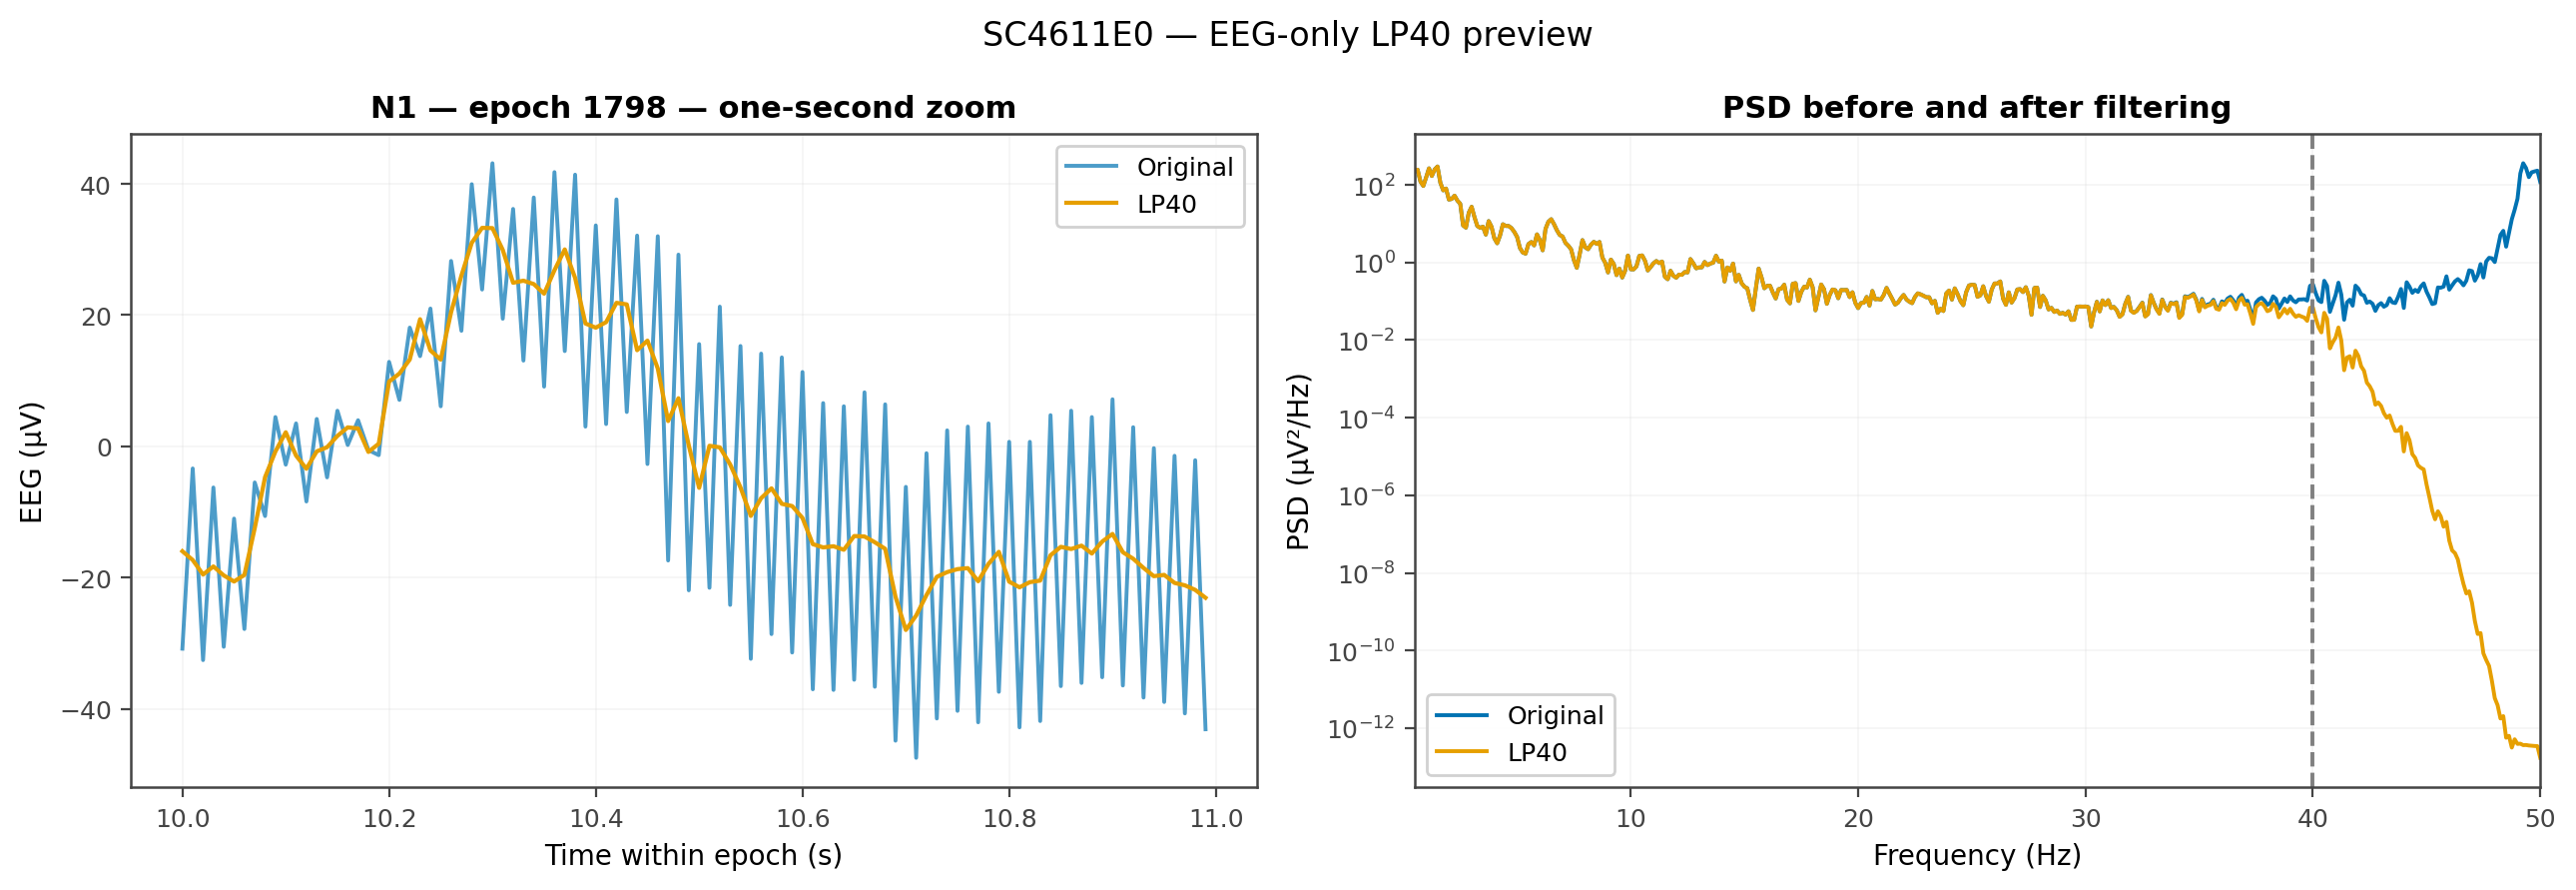

In [ ]:
from scipy.signal import butter, sosfiltfilt, welch

LP40_PREPROCESS_VERSION = 1
LP40_SETTINGS = {
    "cutoff_hz": 40.0,
    "order_per_pass": 4,
    "padtype": "odd",
}

def filtrar_eeg_lp40(eeg, fs):
    sos = butter(
        LP40_SETTINGS["order_per_pass"],
        LP40_SETTINGS["cutoff_hz"],
        btype="lowpass",
        fs=fs,
        output="sos",
    )
    return sosfiltfilt(
        sos,
        eeg,
        axis=-1,
        padtype=LP40_SETTINGS["padtype"],
    )


rec_preview = rec_inspecao_68
assert rec_preview.meta["record"] == "SC4611E0"

epoca_preview = 1798
assert rec_preview.labels[epoca_preview] == "N1"

fs = float(rec_preview.fs)

# Cópia em µV para os gráficos.
original = rec_preview.epochs["eeg"][epoca_preview] * 1e6
filtrado = filtrar_eeg_lp40(original, fs)

assert np.isfinite(filtrado).all()

tempo = np.arange(len(original)) / fs
zoom = (tempo >= 10) & (tempo < 11)

parametros_psd = {
    "fs": fs,
    "window": "hann",
    "nperseg": int(8 * fs),
    "noverlap": int(4 * fs),
    "detrend": "constant",
    "scaling": "density",
}

frequencias, psd_original = welch(original, **parametros_psd)
_, psd_filtrado = welch(filtrado, **parametros_psd)

fig_lp40_preview_68, axes = plt.subplots(
    1, 2, figsize=(13, 4.5)
)

axes[0].plot(
    tempo[zoom], original[zoom],
    label="Original", alpha=0.7,
)
axes[0].plot(
    tempo[zoom], filtrado[zoom],
    label="LP40", linewidth=1.5,
)
axes[0].set(
    title="N1 — epoch 1798 — one-second zoom",
    xlabel="Time within epoch (s)",
    ylabel="EEG (µV)",
)

# Os PSDs usam os 30 segundos completos.
axes[1].semilogy(
    frequencias, psd_original, label="Original"
)
axes[1].semilogy(
    frequencias, psd_filtrado, label="LP40"
)
axes[1].axvline(40, color="grey", linestyle="--")
axes[1].set(
    title="PSD before and after filtering",
    xlabel="Frequency (Hz)",
    ylabel="PSD (µV²/Hz)",
    xlim=(0.5, 50),
)

for ax in axes:
    ax.grid(True, alpha=0.25)
    ax.legend()

fig_lp40_preview_68.suptitle("SC4611E0 — EEG-only LP40 preview")
fig_lp40_preview_68.tight_layout()
plt.show()

In [ ]:
from adapter import cached
from time import perf_counter

LP40_FEATURE_VERSION = 1

def preparar_lp40_gravacao_68(psg):
    psg = Path(psg).resolve()
    record_id = psg.name.removesuffix("-PSG.edf")

    assert record_id[:5] in DEVELOPMENT_GROUPS_68

    marcacoes = list(
        psg.parent.glob(f"{psg.name[:6]}*-Hypnogram.edf")
    )
    assert len(marcacoes) == 1

    referencia = next(
        dados for dados in b0_gravacoes_68
        if dados["record"] == record_id
    )

    chave = {
        "course_revision": COURSE_REVISION,
        "files": [
            (p.name, p.stat().st_size, p.stat().st_mtime_ns)
            for p in (psg, marcacoes[0])
        ],
        "load": {"fs_target": 100.0, "epoch_s": 30.0},
        "runtime": {
            nome: runtime_versions[nome]
            for nome in ("python", "numpy", "scipy", "mne")
        },
        "preprocessing": {
            "version": LP40_PREPROCESS_VERSION,
            "settings": dict(LP40_SETTINGS),
            "channels": ["eeg"],
            "application": "sosfiltfilt, per epoch, axis=-1",
        },
        "features": {
            "version": LP40_FEATURE_VERSION,
            "base_version": B0_FEATURE_VERSION,
            "relative_version": F2_FEATURE_VERSION,
            "spectral_method": "welch",
            "names": nomes_features_f2_68,
        },
    }

    def calcular():
        rec = carregar_gravacao_inspecao_68(record_id)

        # Filtrar o EEG em volts; EOG e EMG mantêm os valores carregados.
        rec_filtrado = type(rec)(
            group=rec.group,
            fs=rec.fs,
            epochs={
                **rec.epochs,
                "eeg": filtrar_eeg_lp40(rec.epochs["eeg"], rec.fs),
            },
            labels=rec.labels,
            meta=dict(rec.meta),
        )

        X11, labels, participante = track_b0_68.extract_features(
            rec_filtrado,
            cfg={"spectral_method": "welch"},
        )

        potencias = X11[:, indices_bandas_f2_68]
        assert np.isfinite(potencias).all()
        assert (potencias >= 0).all()

        total = potencias.sum(axis=1, keepdims=True)
        relativas = np.divide(
            potencias,
            total,
            out=np.zeros_like(potencias, dtype=float),
            where=total > 0,
        )

        return {
            "record": record_id,
            "X": np.column_stack([X11, relativas]),
            "y": labels,
            "groups": np.repeat(participante, len(labels)),
            "feature_names": list(nomes_features_f2_68),
        }

    dados = cached(
        "viggy_lp40_features",
        chave,
        calcular,
        CACHE_VIGGY,
    )

    # Confirmar a comparação nas mesmas épocas e participantes.
    assert dados["record"] == record_id
    assert dados["feature_names"] == nomes_features_f2_68
    assert dados["X"].shape == (len(referencia["y"]), 16)
    assert np.isfinite(dados["X"]).all()

    np.testing.assert_array_equal(dados["y"], referencia["y"])
    np.testing.assert_array_equal(dados["groups"], referencia["groups"])

    # Confirmar que as características de EOG/EMG não foram alteradas.
    indices_auxiliares = [
        nomes_features_b0.index(nome)
        for nome in ("eog_movement", "emg_rms")
    ]
    np.testing.assert_allclose(
        dados["X"][:, indices_auxiliares],
        referencia["X"][:, indices_auxiliares],
        rtol=1e-12,
        atol=0,
    )

    return dados


psg_lp40_teste = next(TRAIN_DIR.rglob("SC4611E0-PSG.edf"))

inicio = perf_counter()
lp40_teste = preparar_lp40_gravacao_68(psg_lp40_teste)

print("\nGravação:", lp40_teste["record"])
print("Épocas:", len(lp40_teste["y"]))
print("Características:", lp40_teste["X"].shape[1])
print("Labels, participantes e EOG/EMG confirmados.")
print(f"Tempo de preparação: {perf_counter() - inicio:.1f} segundos")

[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_8e4c87d8ba0e.pkl

Gravação: SC4611E0
Épocas: 2644
Características: 16
Labels, participantes e EOG/EMG confirmados.
Tempo de preparação: 51.1 segundos


In [ ]:
# LP40 — preparar as gravações dos mesmos 68 participantes.
assert len(ficheiros_b0_68) == 133
assert {
    p.name[:5] for p in ficheiros_b0_68
} == set(DEVELOPMENT_GROUPS_68)

lp40_gravacoes_68 = []
inicio_lp40_68 = perf_counter()

for numero, psg in enumerate(ficheiros_b0_68, start=1):
    inicio_gravacao = perf_counter()

    dados = preparar_lp40_gravacao_68(psg)
    lp40_gravacoes_68.append(dados)

    segundos = perf_counter() - inicio_gravacao
    minutos_total = (perf_counter() - inicio_lp40_68) / 60

    print(
        f"[{numero:03d}/133] {dados['record']} | "
        f"{len(dados['y'])} épocas | "
        f"{segundos:.1f} s | "
        f"total: {minutos_total:.1f} min",
        flush=True,
    )

# Juntar apenas as tabelas de características e identificadores.
X_lp40_68 = np.concatenate([
    dados["X"] for dados in lp40_gravacoes_68
])
y_lp40_68 = np.concatenate([
    dados["y"] for dados in lp40_gravacoes_68
])
groups_lp40_68 = np.concatenate([
    dados["groups"] for dados in lp40_gravacoes_68
])
record_ids_lp40_68 = np.concatenate([
    np.repeat(dados["record"], len(dados["y"]))
    for dados in lp40_gravacoes_68
])

# Confirmar exatamente as mesmas épocas e a mesma ordem de F2.
assert X_lp40_68.shape == X_f2_68.shape

np.testing.assert_array_equal(y_lp40_68, y_b0_68)
np.testing.assert_array_equal(groups_lp40_68, groups_b0_68)
np.testing.assert_array_equal(
    record_ids_lp40_68, record_ids_b0_68
)

print("\nLP40 — PREPARAÇÃO CONCLUÍDA")
print("Participantes:", len(set(groups_lp40_68)))
print("Gravações:", len(lp40_gravacoes_68))
print("Dimensão:", X_lp40_68.shape)
print("Labels, participantes e ordem das épocas confirmados.")

[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_b030fdacb58c.pkl
[001/133] SC4001E0 | 2650 épocas | 48.2 s | total: 0.8 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_9c9b545aef4e.pkl
[002/133] SC4002E0 | 2829 épocas | 51.6 s | total: 1.7 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_60dc679ba963.pkl
[003/133] SC4011E0 | 2802 épocas | 54.1 s | total: 2.6 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_7e15ac284305.pkl
[004/133] SC4012E0 | 2848 épocas | 48.6 s | total: 3.4 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_5316b789b31a.pkl
[005/133] SC4021E0 | 2804 épocas | 56.0 s | total: 4.3 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_4d5592aefef2.pkl
[006/133] SC4022E0 | 2755 épocas | 48.0 s | total: 5.1 min
[cache] viggy_lp40_features: computed and saved _cache_viggy_lp40_features_7f22feb5b2d9.pkl
[0

In [ ]:
# LP40 — avaliar nos mesmos cinco folds do B0 e do F2.

resultados_lp40_68, tabela_lp40_68 = avaliar_experiencia_68(
    nome="LP40_68_fixed_AE",
    X=X_lp40_68,
    nomes_features=nomes_features_f2_68,
    versao_features=LP40_FEATURE_VERSION,
    detalhes={
        "base_feature_version": B0_FEATURE_VERSION,
        "relative_feature_version": F2_FEATURE_VERSION,
        "relative_bands": list(bandas_f2_68),
        "denominator": "sum of the five EEG band powers",
        "normalization_scope": "each epoch independently",
        "spectral_method": "welch",
        "preprocessing": {
            "version": LP40_PREPROCESS_VERSION,
            "method": "Butterworth low-pass",
            "settings": dict(LP40_SETTINGS),
            "channels": ["eeg"],
            "application": "sosfiltfilt, per epoch, axis=-1",
        },
        "training_crop": False,
    },
)

print("\nLP40 — CINCO FOLDS CONCLUÍDOS")
display(tabela_lp40_68.round(3))

kappas_lp40 = tabela_lp40_68["cohens_kappa"]

print(
    "\nKappa médio ± SD entre os cinco folds: "
    f"{kappas_lp40.mean():.3f} ± "
    f"{kappas_lp40.std(ddof=1):.3f}"
)

print(
    "Tempo total de treino: "
    f"{tabela_lp40_68['Treino (min)'].sum():.1f} min"
)

# Comparação direta: mesmas pessoas de treino e teste em cada fold.
comparacao_f2_lp40_68 = pd.DataFrame({
    "F2": tabela_f2_68["cohens_kappa"],
    "LP40": tabela_lp40_68["cohens_kappa"],
})

comparacao_f2_lp40_68["Diferença"] = (
    comparacao_f2_lp40_68["LP40"]
    - comparacao_f2_lp40_68["F2"]
)

print("\nCOMPARAÇÃO DO KAPPA NOS MESMOS FOLDS")
display(comparacao_f2_lp40_68.round(3))


LP40_68_fixed_AE — fold A: a treinar...
Fold A concluído: kappa = 0.756 | treino = 9.11 min

LP40_68_fixed_AE — fold B: a treinar...
Fold B concluído: kappa = 0.719 | treino = 8.49 min

LP40_68_fixed_AE — fold C: a treinar...
Fold C concluído: kappa = 0.736 | treino = 9.20 min

LP40_68_fixed_AE — fold D: a treinar...
Fold D concluído: kappa = 0.716 | treino = 8.88 min

LP40_68_fixed_AE — fold E: a treinar...
Fold E concluído: kappa = 0.751 | treino = 8.89 min

LP40 — CINCO FOLDS CONCLUÍDOS


,cohens_kappa,macro_f1,accuracy,balanced_accuracy,Treino (min)
Fold,,,,,
A,0.756,0.680,0.887,0.675,9.113
B,0.719,0.650,0.863,0.639,8.494
C,0.736,0.650,0.876,0.623,9.202
D,0.716,0.636,0.874,0.600,8.883
E,0.751,0.678,0.880,0.662,8.889



Kappa médio ± SD entre os cinco folds: 0.736 ± 0.018
Tempo total de treino: 44.6 min

COMPARAÇÃO DO KAPPA NOS MESMOS FOLDS


,F2,LP40,Diferença
Fold,,,
A,0.753,0.756,0.003
B,0.718,0.719,0.001
C,0.739,0.736,-0.003
D,0.717,0.716,-0.001
E,0.748,0.751,0.003


In [ ]:
from sklearn.metrics import classification_report

# Juntar as previsões de teste dos cinco folds.
previsoes_lp40_68, relatorio_lp40_68 = juntar_previsoes_68(
    resultados_lp40_68
)

print("LP40 — MÉTRICAS GLOBAIS")
for metrica in [
    "cohens_kappa",
    "macro_f1",
    "accuracy",
    "balanced_accuracy",
]:
    print(f"{metrica}: {relatorio_lp40_68[metrica]:.3f}")

estagios = ["W", "N1", "N2", "N3", "REM"]

print("\nLP40 — RESULTADOS POR ESTÁGIO")
print(classification_report(
    y_b0_68,
    previsoes_lp40_68,
    labels=estagios,
    digits=3,
    zero_division=0,
))

# Comparar F2 e LP40 nas mesmas épocas.
classes_f2 = classification_report(
    y_b0_68,
    previsoes_f2_68,
    labels=estagios,
    output_dict=True,
    zero_division=0,
)

classes_lp40 = classification_report(
    y_b0_68,
    previsoes_lp40_68,
    labels=estagios,
    output_dict=True,
    zero_division=0,
)

comparacao_estagios_f2_lp40_68 = pd.DataFrame([
    {
        "Estágio": estagio,
        "Recall F2": classes_f2[estagio]["recall"],
        "Recall LP40": classes_lp40[estagio]["recall"],
        "F1 F2": classes_f2[estagio]["f1-score"],
        "F1 LP40": classes_lp40[estagio]["f1-score"],
        "Diferença F1": (
            classes_lp40[estagio]["f1-score"]
            - classes_f2[estagio]["f1-score"]
        ),
    }
    for estagio in estagios
]).set_index("Estágio")

print("\nCOMPARAÇÃO POR ESTÁGIO")
display(comparacao_estagios_f2_lp40_68.round(3))

LP40 — MÉTRICAS GLOBAIS
cohens_kappa: 0.736
macro_f1: 0.661
accuracy: 0.876
balanced_accuracy: 0.641

LP40 — RESULTADOS POR ESTÁGIO
              precision    recall  f1-score   support

           W      0.938     0.979     0.958    248341
          N1      0.338     0.129     0.187     17877
          N2      0.767     0.814     0.790     60494
          N3      0.840     0.690     0.758     11610
         REM      0.630     0.593     0.611     22299

    accuracy                          0.876    360621
   macro avg      0.703     0.641     0.661    360621
weighted avg      0.857     0.876     0.864    360621


COMPARAÇÃO POR ESTÁGIO


,Recall F2,Recall LP40,F1 F2,F1 LP40,Diferença F1
Estágio,,,,,
W,0.980,0.979,0.959,0.958,-0.001
N1,0.135,0.129,0.195,0.187,-0.008
N2,0.813,0.814,0.786,0.790,0.003
N3,0.681,0.690,0.751,0.758,0.007
REM,0.581,0.593,0.605,0.611,0.006


In [ ]:
from sklearn.metrics import cohen_kappa_score

linhas = []

for participante in sorted(set(groups_b0_68)):
    mascara = groups_b0_68 == participante

    kappa_f2 = cohen_kappa_score(
        y_b0_68[mascara],
        previsoes_f2_68[mascara],
    )

    kappa_lp40 = cohen_kappa_score(
        y_b0_68[mascara],
        previsoes_lp40_68[mascara],
    )

    linhas.append({
        "Participante": participante,
        "F2": kappa_f2,
        "LP40": kappa_lp40,
        "Diferença": kappa_lp40 - kappa_f2,
    })

comparacao_participantes_f2_lp40_68 = (
    pd.DataFrame(linhas).set_index("Participante")
)

print("OS TRÊS PARTICIPANTES QUE INSPECIONÁMOS")
display(
    comparacao_participantes_f2_lp40_68.loc[
        ["SC461", "SC453", "SC414"]
    ].round(3)
)

diferencas = comparacao_participantes_f2_lp40_68["Diferença"]

print("\nNOS 68 PARTICIPANTES — antes de arredondar:")
print("Kappa aumentou:", int((diferencas > 0).sum()))
print("Kappa diminuiu:", int((diferencas < 0).sum()))
print("Kappa igual:", int((diferencas == 0).sum()))

OS TRÊS PARTICIPANTES QUE INSPECIONÁMOS


,F2,LP40,Diferença
Participante,,,
SC461,0.241,0.271,0.030
SC453,0.763,0.768,0.004
SC414,0.905,0.906,0.000



NOS 68 PARTICIPANTES — antes de arredondar:
Kappa aumentou: 29
Kappa diminuiu: 39
Kappa igual: 0


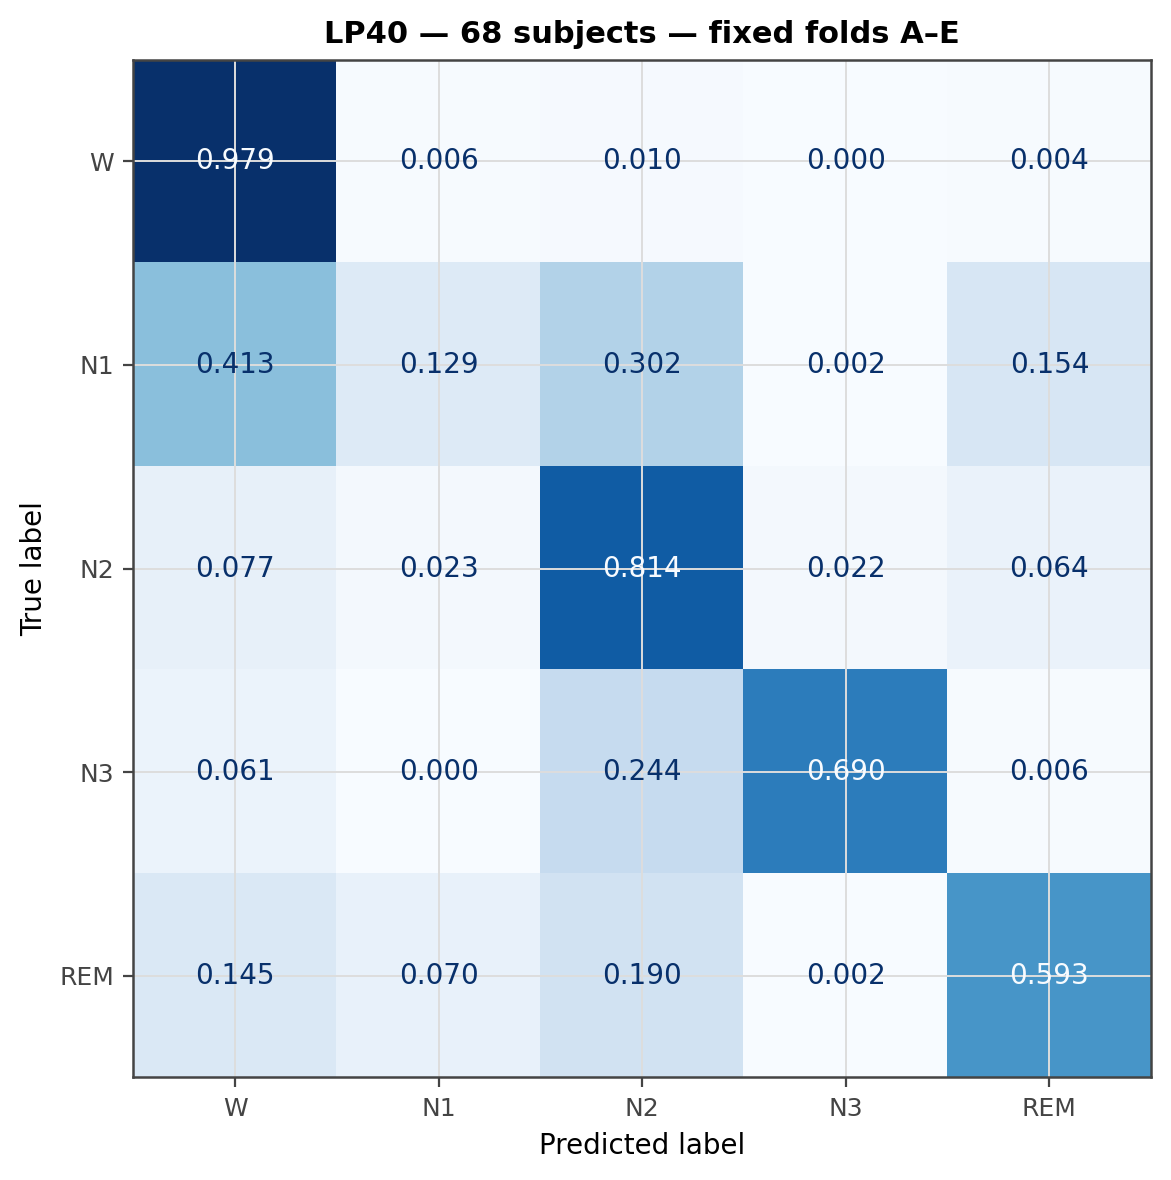

Relatório guardado: /content/drive/MyDrive/CM2013_data/experiments/LP40_68_fixed_AE.json
Imagem guardada: /content/drive/MyDrive/CM2013_data/experiments/LP40_68_fixed_AE_confusion.png


In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

EXPERIMENTS_DIR.mkdir(parents=True, exist_ok=True)

# Matriz de confusão: cada linha soma 100%.
fig_lp40_68, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay.from_predictions(
    y_b0_68,
    previsoes_lp40_68,
    labels=["W", "N1", "N2", "N3", "REM"],
    normalize="true",
    values_format=".3f",
    cmap="Blues",
    colorbar=False,
    ax=ax,
)

ax.set_title("LP40 — 68 subjects — fixed folds A–E")
fig_lp40_68.tight_layout()

destino_imagem = (
    EXPERIMENTS_DIR / "LP40_68_fixed_AE_confusion.png"
)
fig_lp40_68.savefig(
    destino_imagem, dpi=200, bbox_inches="tight"
)
plt.show()

# Recuperar a configuração comum aos cinco folds.
campos_especificos_fold = {
    "fold", "training_subjects", "test_subjects",
    "test_indices", "fit_seconds", "predict_seconds", "report",
}

metadados_lp40 = {
    chave: valor
    for chave, valor in resultados_lp40_68["A"].items()
    if chave not in campos_especificos_fold
}

metricas = [
    "cohens_kappa", "macro_f1",
    "accuracy", "balanced_accuracy",
]

exportacao_lp40 = {
    **metadados_lp40,
    "split_unit": "subject",
    "cv_method": "five fixed folds A–E",
    "n_subjects": len(set(groups_b0_68)),
    "n_epochs": len(y_b0_68),
    "cv_mean_sd_across_folds": {
        metrica: {
            "mean": float(tabela_lp40_68[metrica].mean()),
            "sd": float(tabela_lp40_68[metrica].std(ddof=1)),
        }
        for metrica in metricas
    },
    "sd_ddof": 1,
    "total_fit_seconds": sum(
        resultado["fit_seconds"]
        for resultado in resultados_lp40_68.values()
    ),
    "fold_metrics": (
        tabela_lp40_68.reset_index().to_dict(orient="records")
    ),
    "report": relatorio_lp40_68,
    "kappa_comparison_vs_F2_by_subject": (
        comparacao_participantes_f2_lp40_68
        .reset_index()
        .to_dict(orient="records")
    ),
    "working_decision": (
        "Keep F2 as reference. LP40 produced mixed results, "
        "with a small overall gain and lower N1 performance."
    ),
}

destino_json = EXPERIMENTS_DIR / "LP40_68_fixed_AE.json"
temporario = destino_json.with_suffix(".tmp")

temporario.write_text(
    json.dumps(
        exportacao_lp40,
        default=converter_numpy,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)
temporario.replace(destino_json)

print("Relatório guardado:", destino_json)
print("Imagem guardada:", destino_imagem)